In [1]:
from matplotlib import colors
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

# nice plotting function with cartopy and coastlines. Use robinson projection
import cartopy.crs as ccrs
import cartopy.feature as cf
import matplotlib.pyplot as plt
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from matplotlib.ticker import FixedLocator

# truncate a colormap. eg, lower half of a diverging cmap
def truncate_colormap(cmap, minval=0.0, maxval=1.0, n=100):
    new_cmap = colors.LinearSegmentedColormap.from_list(
        'trunc({n},{a:.2f},{b:.2f})'.format(n=cmap.name, a=minval, b=maxval),
        cmap(np.linspace(minval, maxval, n)))
    return new_cmap

# convert a continous cmap to a graduated discrete cmap with n discrete colors. eg, 5 discrete colors from a continuous cmap
def discrete_colormap(cmap, n):
    cmap = plt.get_cmap(cmap)
    new_cmap = colors.ListedColormap(
        cmap(np.linspace(0, 1, n)))
    return new_cmap

import matplotlib.pyplot as plt
plt.rcParams['svg.fonttype'] = 'none' # to keep text as text in svg output

# write your plotting code below

def plot_map(dataarray, title='', cmap='viridis', cmap_split = '', discrete_cmap=0, vmin=None, vmax=None, borders=False, norm=None, cbar_label= '', cbar_loc = 'bottom', svg=False, grid_labels=False, local_map=False):
    
    if cmap_split=='low':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.0, 0.5)
    elif cmap_split=='high':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.5, 1.0)
    elif cmap_split=='trim':
        custom_cmap = truncate_colormap(plt.get_cmap(cmap), 0.1, 0.9)
    else:
        custom_cmap = plt.get_cmap(cmap)

    if discrete_cmap != 0:
        custom_cmap = discrete_colormap(custom_cmap, discrete_cmap)

    if cbar_label=='':
        cbar_label = dataarray.name
        
    plt.figure(figsize=(12, 8))
    if local_map == False:
        ax = plt.axes(projection=ccrs.Robinson())
    else: # for local maps use PlateCarree projection
        ax = plt.axes(projection=ccrs.PlateCarree())
    # plot only nans in grey. supress cbar
    xr.where(dataarray.isnull(), 1, np.nan).plot(ax=ax, cmap=colors.ListedColormap(['lightgrey']), vmin=1, vmax=1, transform=ccrs.PlateCarree(), add_colorbar=False)
    # plot data
    dataarray.plot(ax=ax, cmap=custom_cmap, vmin=vmin, vmax=vmax, norm=norm, cbar_kwargs={'label': cbar_label, 'location': cbar_loc, 'fraction': 0.06, 'pad': 0.05, 'ticks': np.linspace(vmin + (vmin/discrete_cmap), vmax + (vmax/discrete_cmap), int((discrete_cmap + 1)/2)+1) if discrete_cmap else None}, transform=ccrs.PlateCarree())    
    ax.coastlines() # coastlines for context

    ax.add_feature(cf.OCEAN, facecolor='white', zorder=5)
    if borders: # country borders toggle
        ax.add_feature(cf.BORDERS)

    if grid_labels:
        # show only major longitude/latitude labels using gridlines
        lon_ticks = [-180, -120, -60, 0, 60, 120, 180]
        lat_ticks = [-45, -30, -15, 0, 15, 30, 45]

        gl = ax.gridlines(
            crs=ccrs.PlateCarree(),
            draw_labels=True,
            linewidth=0,
            x_inline=False,
            y_inline=False,
        )
        # show only bottom and left labels
        gl.top_labels = False
        gl.right_labels = False
        gl.bottom_labels = True
        gl.left_labels = True
        gl.xlocator = FixedLocator(lon_ticks)
        gl.ylocator = FixedLocator(lat_ticks)
        gl.xformatter = LongitudeFormatter()
        gl.yformatter = LatitudeFormatter()
        gl.xlabel_style = {'size': 10}
        gl.ylabel_style = {'size': 10}

    ax.set_title(title)
    if svg:
        plt.savefig("../export/map_{}.svg".format(dataarray.name), format='svg', bbox_inches='tight')
    plt.show()

# convert a continous cmap to a graduated discrete cmap with n discrete colors. eg, 5 discrete colors from a continuous cmap
def discrete_colormap(cmap, n):
    cmap = plt.get_cmap(cmap)
    new_cmap = colors.ListedColormap(
        cmap(np.linspace(0, 1, n)))
    return new_cmap

#discrete_colormap('viridis', 5)

# function for calculating glomal mean and std of a given dataarray, both weighted and unweighted
# weight by grid cell area calculated using earth's radius and latitude. i.e. create a weight array with same lat and lon dimensions as da, where weights = cos(lat) and then use xarray's weighted function to calculate mean and std
# area = R * (max_lat - min_lat) * (max_lon - min_lon) * cos(lat) where R is Earth's radius and lat is the latitude of the grid cell in radians.
# Since we are only interested in relative weights, we can ignore the constant R and the lat/lon differences and just use weights = cos(lat) for each grid cell.
def global_stats(da, weighted=True):
    if weighted:
        weights = np.cos(np.deg2rad(da['lat']))
        weighted_da = da.weighted(weights)
        mean = weighted_da.mean(dim=['lat', 'lon'])
        std = weighted_da.std(dim=['lat', 'lon'])
    else:
        mean = da.mean(dim=['lat', 'lon'])
        std = da.std(dim=['lat', 'lon'])
    return mean, std

In [2]:
# load SR trainiing target and create a static mask where there is no vegetation (i.e. where SR is not finite)
sr_target = xr.open_dataarray("../data/SR-target/merged_SR.nc")

#preds = xr.open_dataset("../output_SR/aggregated_sr_scenarios_masked_squarederror.zarr")
preds = xr.open_dataset("../output_SR/aggregated_sr_scenarios_masked.zarr")
nanMask = xr.where(np.isfinite(preds.sr_k0_mean.isel(climate = 0, lu = 0)), np.nan, 1).drop_vars(['climate', 'lu']) # mask with value 1 for missing data

In [ ]:
clusterk6 = xr.open_dataset("../data/climate_clusters.zarr", group="1991_2020")
clusterk6.cluster.plot(cmap = discrete_colormap('Blues', n=7), vmin=-1, vmax=5)

In [3]:
sr_2020 = preds.sel(climate='1991_2020', lu='1991_2020').sr_k6_mean
error = sr_2020 - sr_target
pct_error = (error / sr_target) * 100
normalized_error = error / sr_target.std(dim=['lat', 'lon'])

In [4]:
# Source - https://stackoverflow.com/a/57155553
# Posted by kkawabat
# Retrieved 2026-06-08, License - CC BY-SA 4.0
import math
def internally_studentized_residual(X,Y):
    X = np.array(X, dtype=float)
    Y = np.array(Y, dtype=float)
    mean_X = np.mean(X)
    mean_Y = np.mean(Y)
    n = len(X)
    diff_mean_sqr = np.dot((X - mean_X), (X - mean_X))
    beta1 = np.dot((X - mean_X), (Y - mean_Y)) / diff_mean_sqr
    beta0 = mean_Y - beta1 * mean_X
    y_hat = beta0 + beta1 * X
    residuals = Y - y_hat
    h_ii = (X - mean_X) ** 2 / diff_mean_sqr + (1 / n)
    Var_e = math.sqrt(sum((Y - y_hat) ** 2)/(n-2))
    SE_regression = Var_e*((1-h_ii) ** 0.5)
    studentized_residuals = residuals/SE_regression
    return studentized_residuals

def deleted_studentized_residual(X,Y):
    #formula from https://newonlinecourses.science.psu.edu/stat501/node/401/
    r = internally_studentized_residual(X,Y)
    n = len(r)
    return [r_i*math.sqrt((n-2-1)/(n-2-r_i**2)) for r_i in r]

# get standardized residuals. Flatten and drop nans before passing to the function, then reshape back to original shape and create a new dataarray with same coords and dims as sr_target

# faltten and drop nans
error_flat = error.values.flatten()
sr_target_flat = sr_target.values.flatten()
mask = np.isfinite(error_flat) & np.isfinite(sr_target_flat)
error_flat_masked = error_flat[mask]
sr_target_flat_masked = sr_target_flat[mask]
# get standardized residuals
standardized_residual_flat = error_flat_masked / np.std(sr_target_flat_masked)
# reshape back to original shape
standardized_residual = np.full_like(error_flat, np.nan)
standardized_residual[mask] = standardized_residual_flat
standardized_residual = standardized_residual.reshape(error.shape)
# create new dataarray
standardized_residual_da = xr.DataArray(standardized_residual, coords=sr_target.coords, dims=sr_target.dims, name='standardized_residual')
# plot_map(standardized_residual_da, vmin=-2, vmax=2, cmap='bwr', title='Standardized Residuals of $S_R$ Predictions (1991-2020)', cbar_label='Standardized Residuals')
# outlierPreds = xr.where(np.abs(standardized_residual_da) > 2, 1, np.nan)

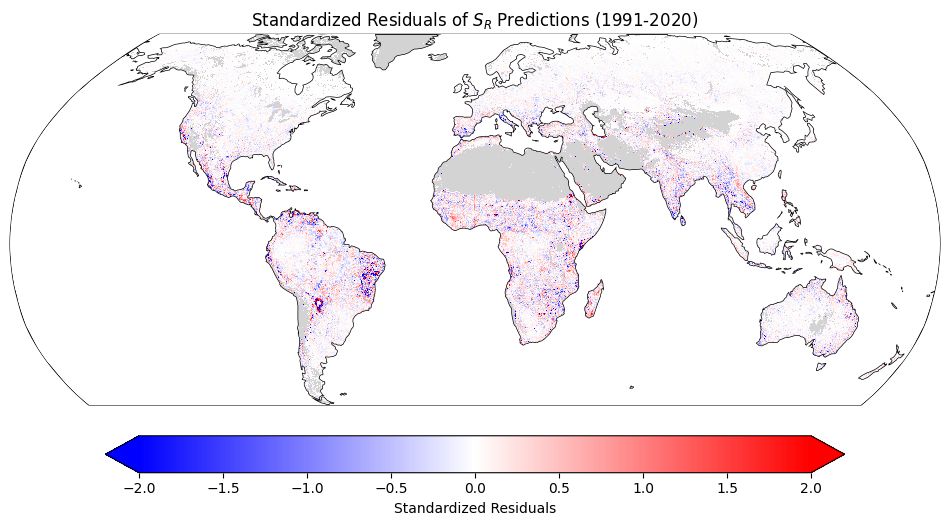

In [5]:
plot_map(standardized_residual_da, vmin=-2, vmax=2, cmap='bwr', title='Standardized Residuals of $S_R$ Predictions (1991-2020)', cbar_label='Standardized Residuals')

In [6]:
outlierPreds = xr.where(np.abs(standardized_residual_da) > 2, 1, np.nan)

In [9]:
outlierPreds.sum()

<xarray.DataArray 'standardized_residual' ()> Size: 8B
array(21072.)

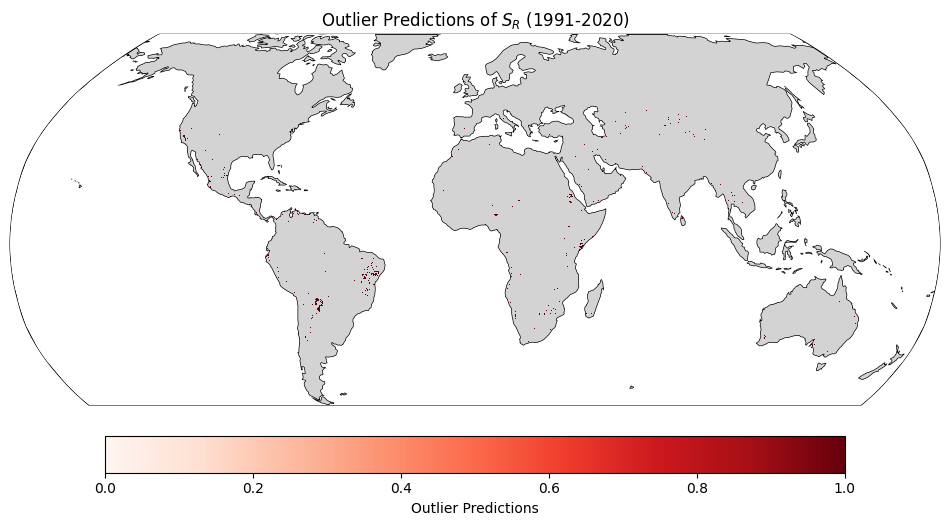

In [7]:
plot_map(outlierPreds, vmin=0, vmax=1, cmap='Reds', title='Outlier Predictions of $S_R$ (1991-2020)', cbar_label='Outlier Predictions', cbar_loc='bottom')

In [ ]:
extremeError = xr.where(np.abs(pct_error) > 80, 1, np.nan).drop_vars(['climate', 'lu'])
# mask preds with extreme error mask
predsErrorMasked = preds['sr_mean'].where(extremeError != 1)
#plot_map(extremeError, vmin=0, vmax=1, cmap='Reds', title='Extreme Errors in $S_R$ Predictions (1991-2020)', cbar_label='Percentage Error')

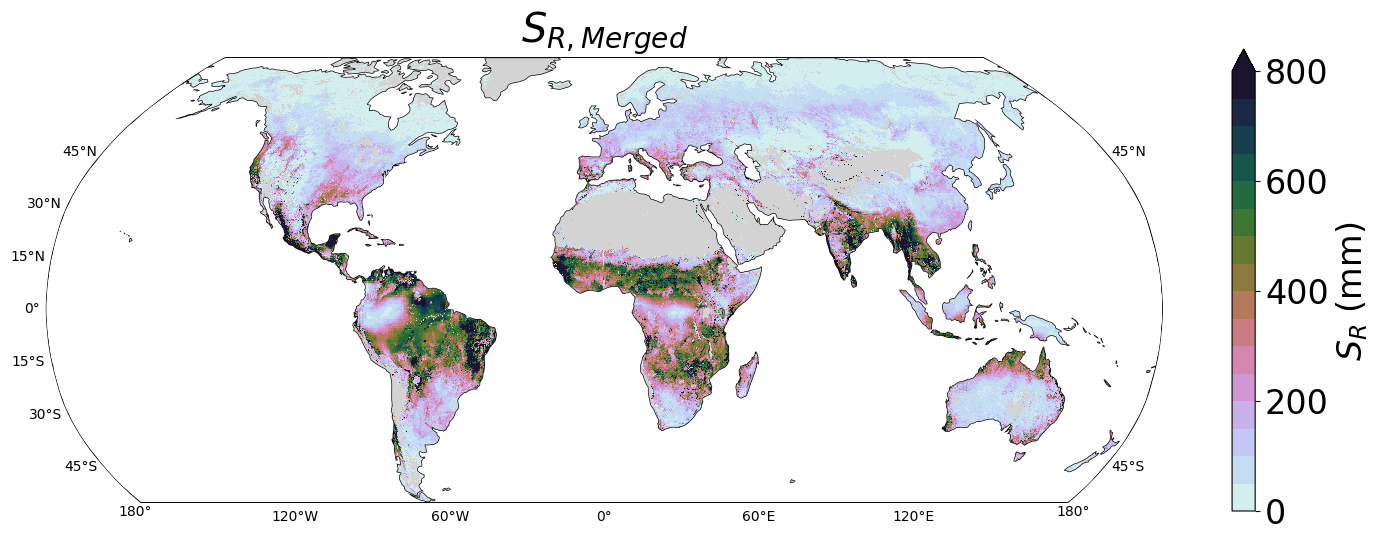

In [43]:
plt.rcParams['font.size'] = 24
plot_map(sr_target, title='$S_{R, Merged}$', cmap='cubehelix_r', cmap_split='trim', discrete_cmap=16, vmin = 0, vmax = 800, borders=False, cbar_label='$S_R$ (mm)', grid_labels=True)

In [4]:
# create a grid area array for weighting.
# It has the area in square kilometers for each grid cell, calculated using the formula: area = R^2 * (lon2 - lon1) * (sin(lat2) - sin(lat1)),
# where R is Earth's radius (6371 km), lat1 and lat2 are the latitudes of the grid cell edges in radians,
# and lon1 and lon2 are the longitudes of the grid cell edges in radians.
R = 6371  # Earth's radius in kilometers
lat_edges = np.deg2rad(sr_2020['lat'].values)  # convert latitudes to radians
lon_edges = np.deg2rad(sr_2020['lon'].values)  # convert longitudes to radians
lat1 = lat_edges - np.deg2rad(0.05/2) # assuming 0.05 degree grid cells, calculate the edges
lat2 = lat_edges + np.deg2rad(0.05/2)
lon1 = lon_edges - np.deg2rad(0.05/2)
lon2 = lon_edges + np.deg2rad(0.05/2)
# create 2d arrays for lat1, lat2, lon1, lon2 to match the dimensions of the grid
lat1_2d, lon1_2d = np.meshgrid(lat1, lon1, indexing='ij')
lat2_2d, lon2_2d = np.meshgrid(lat2, lon2, indexing='ij')
area = R**2 * (lon2_2d - lon1_2d) * (np.sin(lat2_2d) - np.sin(lat1_2d))  # area in square kilometers
area_da = xr.DataArray(area, coords=sr_2020.coords, dims=sr_2020.dims, name='grid_cell_area')
#plot_map(area_da, title='Grid Cell Area', cmap='viridis', cbar_label='Area (sq km)', grid_labels=True)

In [5]:
# get sr_2020 global mean and global sum using area_da
# sr_2020 is in mm. area_da is in square kilometers. To get the global sum in cubic kilometers, we can multiply sr_2020 by area_da and then sum over lat and lon. To get the global mean in mm, we can divide the global sum by the total area of the grid cells that have valid data (i.e. not NaN).
total_area = area_da.where(~sr_2020.isnull()).sum(dim=['lat', 'lon'])
global_sum = (sr_2020 * area_da).where(~sr_2020.isnull()).sum(dim=['lat', 'lon'])  # in mm * square kilometers
global_mean = global_sum / total_area  # in mm
print(f"Global mean SR for 2020: {global_mean.values:.2f} mm")
print(f"Global sum of SR for 2020: {global_sum.values/ 1000000:.2f} cubic kilometers")

Global mean SR for 2020: 227.27 mm
Global sum of SR for 2020: 24156.37 cubic kilometers


In [7]:
# global mean using the function, for comparison
sr2020_mean, sr2020_std = global_stats(sr_2020, weighted=True)
print(f"Global mean SR for 2020 (weighted): {sr2020_mean.values:.2f} mm")
print(f"Global std of SR for 2020 (weighted): {sr2020_std.values:.2f} mm")

Global mean SR for 2020 (weighted): 227.27 mm
Global std of SR for 2020 (weighted): 213.09 mm


In [8]:
sr_1990 = preds.sel(climate='1961_1990', lu='1961_1990').sr_k6_mean
#plot_map(sr_1990, title='$S_{R, 1991-2020}$', cmap='cubehelix_r', cmap_split='trim', discrete_cmap=16, vmin = 0, vmax = 800, borders=False, cbar_label='$S_R$ (mm)', grid_labels=True)
#sr_1990.drop_vars(['climate', 'lu']).rename('sr').to_netcdf("../export/sr_1961_1990.nc")
#sr_2020.drop_vars(['climate', 'lu']).rename('sr').to_netcdf("../export/sr_1991_2020.nc")

In [ ]:
plot_map(error.coarsen(lat=5, lon=5).median(), vmin=-180, vmax=180, cmap='bwr', discrete_cmap=9, title='Error in $S_R$ Predictions (1991-2020)', cbar_label='Error (mm)')

In [ ]:
plot_map(pct_error.coarsen(lat=5, lon=5).median(), title='Percentage error in predicted $S_{R(1991-2020)}$ ', cmap='bwr', discrete_cmap=11, vmin=-110, vmax=110, borders=False, cbar_label='Percentage error %', grid_labels=False)

In [ ]:
# histogram of error
plt.figure(figsize=(10, 6))
pct_error_vals = pct_error.values.flatten()
pct_error_vals = pct_error_vals[np.isfinite(pct_error_vals)]  # remove nans
plt.hist(pct_error_vals, bins=np.linspace(-150, 150, 151), color='skyblue', edgecolor=None)
plt.title('Percentage Error in $S_R$ Predictions (1991-2020)', fontsize=16)
#plt.yscale('log')  # use log scale for y axis to better show the distribution
plt.xlabel('Percentage Error (%)', fontsize=14)
plt.ylabel('Frequency', fontsize=14)
plt.grid(axis='y', alpha=0.75)
plt.show()

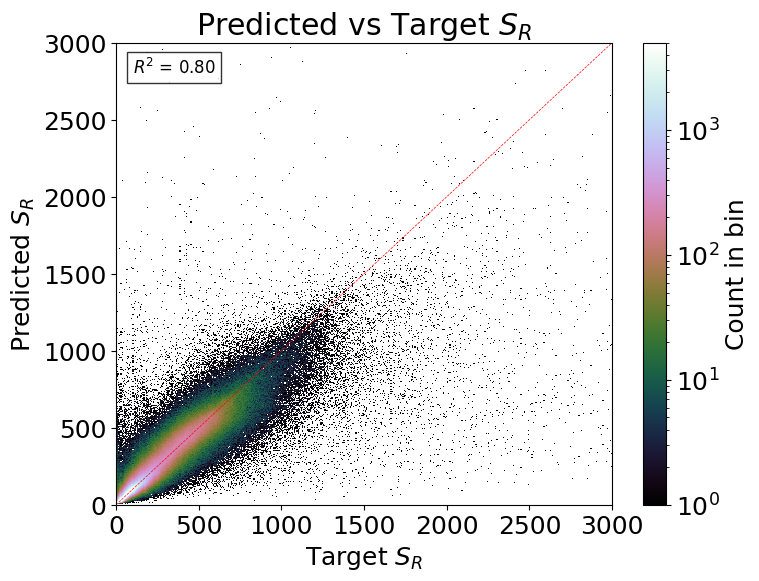

In [ ]:
# predicted vs target as a 2D histogram
from matplotlib.colors import LogNorm
norm = LogNorm(vmin=1, vmax=5000) # log scale for better visibility of dense areas
# mutually mask the two arrays to ensure we only compare valid data points
valid_mask = np.isfinite(sr_target) & np.isfinite(sr_2020)
sr_target_valid = sr_target.where(valid_mask, drop=True)
sr_2020_valid = sr_2020.where(valid_mask, drop=True)
sr_target_flat = sr_target_valid.values.flatten()
sr_target_flat = sr_target_flat[~np.isnan(sr_target_flat)] # remove any remaining NaNs
sr_2020_flat = sr_2020_valid.values.flatten()
sr_2020_flat = sr_2020_flat[~np.isnan(sr_2020_flat)] # remove any remaining NaNs
# calc R2
r2 = np.corrcoef(sr_target_flat, sr_2020_flat)[0, 1]**2

plt.rcParams['font.size'] = 18
plt.figure(figsize=(8, 6))
plt.hist2d(sr_target_flat, sr_2020_flat, bins=5000, cmap='cubehelix', norm=norm) # log scale for better visibility
plt.colorbar(label='Count in bin')
plt.xlabel('Target $S_R$')
plt.ylabel('Predicted $S_R$')
plt.title('Predicted vs Target $S_R$')
plt.plot([0, 3000], [0, 3000], 'r--', linewidth=0.5) # 1:1 line for reference
# annotate R2 on the plot
plt.text(100, 2800, f'$R^2$ = {r2:.2f}', fontsize=12, bbox=dict(facecolor='white', alpha=0.8))
plt.xlim(0, 3000)
plt.ylim(0, 3000)
plt.show()

In [10]:
sr_clim_1901_1930_LU_PI = preds.sel(climate='1901_1930', lu='pre-industrial').sr_k6_mean
sr_clim_1901_1930_LU_1991_2020 = preds.sel(climate='1901_1930', lu='1991_2020').sr_k6_mean
sr_clim_1991_2020_LU_PI = preds.sel(climate='1991_2020', lu='pre-industrial').sr_k6_mean
sr_clim_1991_2020_LU_1991_2020 = preds.sel(climate='1991_2020', lu='1991_2020').sr_k6_mean
sr_clim_1901_1930_LU_Intact = preds.sel(climate='1901_1930', lu='intact').sr_k6_mean
deltaSR_Intact_to_Present = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1901_1930_LU_Intact
deltaSR_Intact_to_PI = sr_clim_1901_1930_LU_PI - sr_clim_1901_1930_LU_Intact
deltaSR = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1901_1930_LU_PI
deltaSR_clim = sr_clim_1991_2020_LU_PI - sr_clim_1901_1930_LU_PI
deltaSR_LU = sr_clim_1901_1930_LU_1991_2020 - sr_clim_1901_1930_LU_PI
deltaSR_interaction = deltaSR - deltaSR_clim - deltaSR_LU

pct_deltaSR = deltaSR/sr_clim_1901_1930_LU_PI * 100
abs_pct_deltaSR = np.abs(pct_deltaSR)

In [5]:
sr_clim_1901_1930_LU_PI = preds.sel(climate='1901_1930', lu='pre-industrial').sr_k6_mean
sr_clim_1901_1930_LU_1901_1930 = preds.sel(climate='1901_1930', lu='1901_1930').sr_k6_mean
sr_clim_1901_1930_LU_1991_2020 = preds.sel(climate='1901_1930', lu='1991_2020').sr_k6_mean
sr_clim_1991_2020_LU_PI = preds.sel(climate='1991_2020', lu='pre-industrial').sr_k6_mean
sr_clim_1991_2020_LU_1901_1930 = preds.sel(climate='1991_2020', lu='1901_1930').sr_k6_mean
sr_clim_1991_2020_LU_1991_2020 = preds.sel(climate='1991_2020', lu='1991_2020').sr_k6_mean
sr_clim_1901_1930_LU_Intact = preds.sel(climate='1901_1930', lu='intact').sr_k6_mean
sr_clim_1991_2020_LU_Intact = preds.sel(climate='1991_2020', lu='intact').sr_k6_mean
sr_clim_1961_1990_LU_1961_1990 = preds.sel(climate='1961_1990', lu='1961_1990').sr_k6_mean
sr_clim_1961_1990_LU_1991_2020 = preds.sel(climate='1961_1990', lu='1991_2020').sr_k6_mean
sr_clim_1991_2020_LU_1961_1990 = preds.sel(climate='1991_2020', lu='1961_1990').sr_k6_mean
deltaSR_Intact_to_Present = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1901_1930_LU_Intact
deltaSR_Intact_to_PI = sr_clim_1901_1930_LU_PI - sr_clim_1901_1930_LU_Intact
deltaSR_Intact_to_1901 = sr_clim_1901_1930_LU_1901_1930 - sr_clim_1901_1930_LU_Intact
deltaSR_PI_to_1901 = sr_clim_1901_1930_LU_1901_1930 - sr_clim_1901_1930_LU_PI
deltaSR_20thC = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1901_1930_LU_1901_1930
deltaSR_clim = sr_clim_1991_2020_LU_1901_1930 - sr_clim_1901_1930_LU_1901_1930
deltaSR_LU = sr_clim_1901_1930_LU_1991_2020 - sr_clim_1901_1930_LU_1901_1930
deltaSR_interaction = deltaSR_20thC - deltaSR_clim - deltaSR_LU
deltaSR_pnv = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1991_2020_LU_Intact
deltaSR_recent = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1961_1990_LU_1961_1990
deltaSR_recent_clim = sr_clim_1991_2020_LU_1961_1990 - sr_clim_1961_1990_LU_1961_1990
deltaSR_recent_LU = sr_clim_1961_1990_LU_1991_2020 - sr_clim_1961_1990_LU_1961_1990
deltaSR = deltaSR_20thC

In [ ]:
# export
deltaSR_recent.to_netcdf("../export/deltaSR_recent.nc")
deltaSR_recent_clim.drop_vars('lu').to_netcdf("../export/deltaSR_recent_clim.nc")
deltaSR_recent_LU.drop_vars('climate').to_netcdf("../export/deltaSR_recent_LU.nc")

/tmp/ipykernel_3797712/1711399785.py:3: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  deltaSR_recent_clim.drop('lu').to_netcdf("../export/deltaSR_recent_clim.nc")
/tmp/ipykernel_3797712/1711399785.py:4: FutureWarning: dropping variables using `drop` is deprecated; use drop_vars.
  deltaSR_recent_LU.drop('climate').to_netcdf("../export/deltaSR_recent_LU.nc")


In [6]:
sr_clim_1901_1930_LU_1901_1930.to_netcdf("../export/sr_1901_1930.nc")

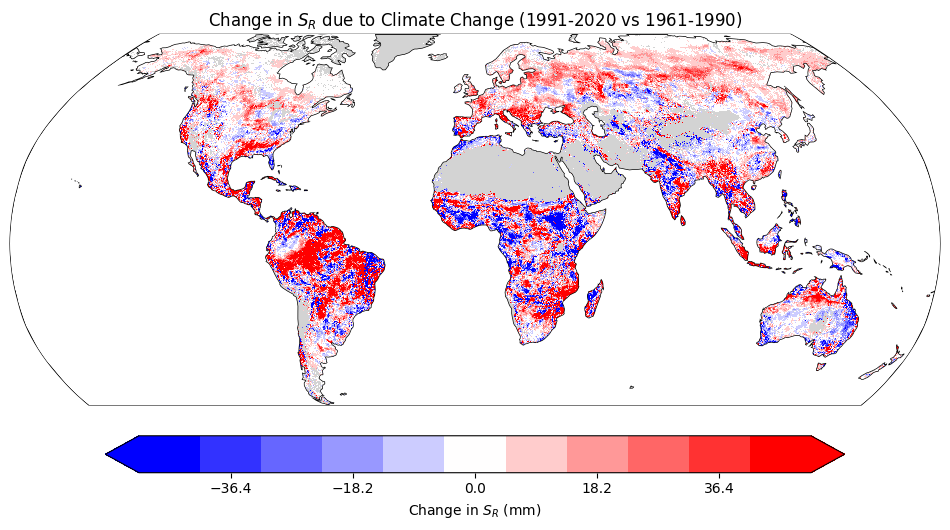

In [7]:
plot_map(deltaSR_recent_clim, vmin=-50, vmax=50, cmap='bwr', discrete_cmap=11, title='Change in $S_R$ due to Climate Change (1991-2020 vs 1961-1990)', cbar_label='Change in $S_R$ (mm)', cbar_loc='bottom')

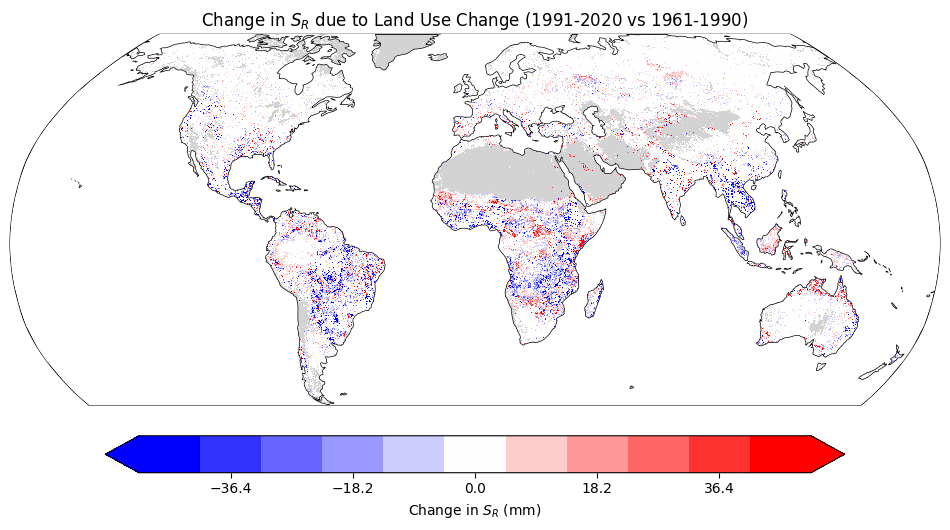

In [8]:
plot_map(deltaSR_recent_LU, vmin=-50, vmax=50, cmap='bwr', discrete_cmap=11, title='Change in $S_R$ due to Land Use Change (1991-2020 vs 1961-1990)', cbar_label='Change in $S_R$ (mm)', cbar_loc='bottom')

In [8]:
# stats
global_mean_deltaSR_recent, global_std_deltaSR_recent = global_stats(deltaSR_recent, weighted=True)
global_mean_deltaSR_recent_clim, global_std_deltaSR_recent_clim = global_stats(deltaSR_recent_clim, weighted=True)
global_mean_deltaSR_recent_LU, global_std_deltaSR_recent_LU = global_stats(deltaSR_recent_LU, weighted=True)
print(f"Global mean change in SR (1991-2020 vs 1961-1990): {global_mean_deltaSR_recent.values:.2f} mm")
print(f"Global std change in SR (1991-2020 vs 1961-1990): {global_std_deltaSR_recent.values:.2f} mm")
print(f"Global mean change in SR due to climate change (1991-2020 vs 1961-1990): {global_mean_deltaSR_recent_clim.values:.2f} mm")
print(f"Global std change in SR due to climate change (1991-2020 vs 1961-1990): {global_std_deltaSR_recent_clim.values:.2f} mm")
print(f"Global mean change in SR due to land use change (1991-2020 vs 1961-1990): {global_mean_deltaSR_recent_LU.values:.2f} mm")
print(f"Global std change in SR due to land use change (1991-2020 vs 1961-1990): {global_std_deltaSR_recent_LU.values:.2f} mm")

Global mean change in SR (1991-2020 vs 1961-1990): 7.35 mm
Global std change in SR (1991-2020 vs 1961-1990): 59.17 mm
Global mean change in SR due to climate change (1991-2020 vs 1961-1990): 8.54 mm
Global std change in SR due to climate change (1991-2020 vs 1961-1990): 60.68 mm
Global mean change in SR due to land use change (1991-2020 vs 1961-1990): -1.21 mm
Global std change in SR due to land use change (1991-2020 vs 1961-1990): 17.79 mm


In [34]:
deltaSR.to_netcdf("../export/deltaSR_20thC.nc")

In [52]:
abs_pct_deltaSR_mean = global_stats(abs_pct_deltaSR, weighted=True)[0]

In [15]:
# export these to netcdf for plotting in GIS
deltaSR.rename('deltaSR').to_netcdf("../export/deltaSR_PI_to_present.nc")
deltaSR_clim.rename('deltaSR_clim').to_netcdf("../export/deltaSR_clim_PI_to_present.nc")
deltaSR_LU.rename('deltaSR_LU').to_netcdf("../export/deltaSR_LU_PI_to_present.nc")
deltaSR_interaction.rename('deltaSR_interaction').to_netcdf("../export/deltaSR_interaction_PI_to_present.nc")

In [11]:
pct_deltaSR_Intact_to_PI = deltaSR_Intact_to_PI * 100 / sr_clim_1901_1930_LU_PI

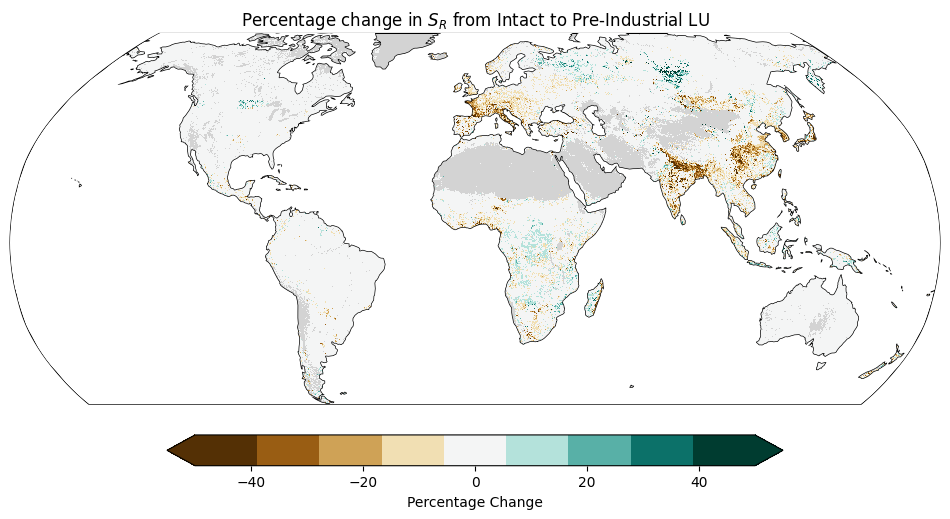

In [17]:
plot_map(pct_deltaSR_Intact_to_PI, title='Percentage change in $S_R$ from Intact to Pre-Industrial LU', cmap='BrBG', vmin=-50, vmax=50, discrete_cmap = 9, cbar_label='Percentage Change', grid_labels=False)

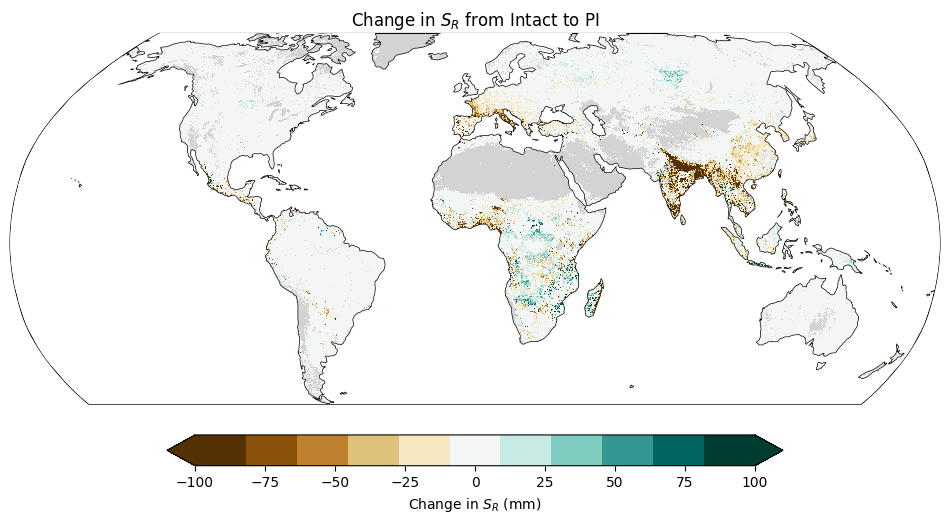

In [18]:
plot_map(deltaSR_Intact_to_PI, title='Change in $S_R$ from Intact to PI', cmap='BrBG', vmin=-100, vmax=100, discrete_cmap=11, cbar_label='Change in $S_R$ (mm)', grid_labels=False)

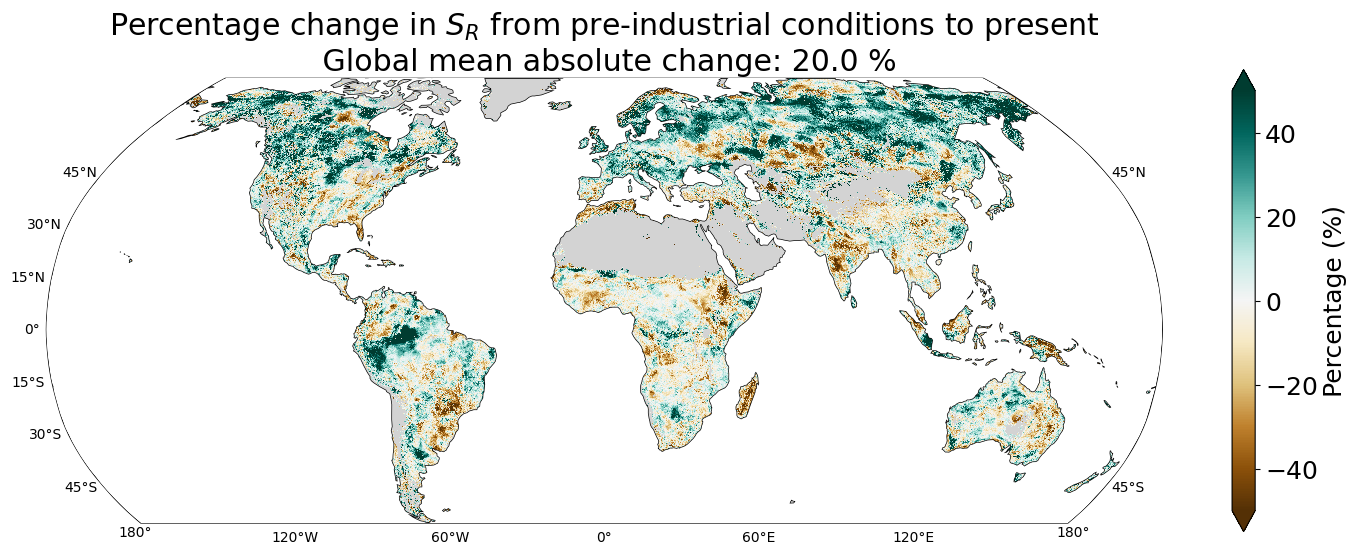

In [30]:
plt.rcParams['font.size'] = 18
plot_map(pct_deltaSR, title=f'Percentage change in $S_R$ from pre-industrial conditions to present \n Global mean absolute change: {global_stats(abs_pct_deltaSR)[0]:.1f} %', cmap='BrBG', vmin=-50, vmax=50, borders=False, cbar_label='Percentage (%)', grid_labels=True)

In [12]:
# aggregate by biome
# load TEOW biome 0.05 raster
biome = xr.open_dataarray("../data/TEOW_biomes.nc")
# assign 0 to nans and convert to int
biome = xr.where(np.isfinite(biome), biome, 0).astype(int)
ocean = xr.where(biome == 0, 1, np.nan)

# create biomeStat xarray dataset
# make biome a dimension and the coordinates are the unique biome values.
# Then add the other variables as data variables
biomeStats_ds = xr.Dataset(
    data_vars={
        'biome': biome,
        'area': area_da,
        'SR_present': sr_clim_1991_2020_LU_1991_2020.rename('SR_present').drop_vars(['climate', 'lu']) * area_da, # weight by area for global sum
        'SR_PI': sr_clim_1901_1930_LU_PI.rename('SR_PI').drop_vars(['climate', 'lu']) * area_da, # weight by area for global sum
        'SR_intact': sr_clim_1901_1930_LU_Intact.rename('SR_intact').drop_vars(['climate', 'lu']) * area_da,
        'deltaSR' : deltaSR.rename('deltaSR') * area_da, # weight by area for global sum
        'deltaSR_clim' : deltaSR_clim.rename('deltaSR_clim').drop_vars(['lu']) * area_da,
        'deltaSR_LU' : deltaSR_LU.rename('deltaSR_LU').drop_vars(['climate']) * area_da,
        'pct_deltaSR': pct_deltaSR.rename('pct_deltaSR').drop_vars(['climate', 'lu']) * area_da
        },
    coords={
        'lat': biome['lat'],
        'lon': biome['lon']
    })

# units for SR cand deltaSR are in mm * square kilometers, which is equivalent to cubic kilometers.
# So we can convert to cubic kilometers by dividing by 1 million (since 1 cubic kilometer = 1 million cubic meters and 1 mm * 1 square kilometer = 1 million cubic meters).
# For percentage change, we can keep it as is since it's already a relative measure.

biome_ids = np.unique(biomeStats_ds['biome'].values)
vars_to_keep = ['SR_present', 'SR_PI', 'SR_intact', 'deltaSR', 
                'deltaSR_clim', 'deltaSR_LU', 'pct_deltaSR', 'area']

data_vars = {}
for var in vars_to_keep:
    # For each biome, keep values where biome matches, else NaN
    # biome_ids shape: (B,), ds[var] shape: (lat, lon)
    # Result shape: (lat, lon, biome)
    biome_mask = biomeStats_ds['biome'] == xr.DataArray(biome_ids, dims='biome')  # broadcasts to (lat, lon, biome)
    masked = biomeStats_ds[var].expand_dims(biome=biome_ids).where(biome_mask)
    data_vars[var] = masked

dsBiome = xr.Dataset(data_vars)

#weights = np.cos(np.deg2rad(dsBiome['lat']))
biomeStatsVol = dsBiome.groupby('biome').mean('lat').mean('lon').to_dataframe()
biomeStatsVolSum = dsBiome.groupby('biome').sum('lat').sum('lon').to_dataframe()
#biomeStats['area'] = dsBiome['area'].groupby('biome').sum('lat').sum('lon').values
# drop rows for biomes 0,98,99
biomeStatsVol = biomeStatsVol.drop(index=[0, 98, 99])
biomeStatsVolSum = biomeStatsVolSum.drop(index=[0, 98, 99])

# divide data variables by 1 million to convert from mm * square kilometers to cubic kilometers
for var in ['SR_present', 'SR_PI', 'SR_intact', 'deltaSR', 'deltaSR_clim', 'deltaSR_LU', 'pct_deltaSR']:
    biomeStatsVolSum[var] = biomeStatsVolSum[var] / 1e6

biomeStats = biomeStatsVol.copy()
for var in vars_to_keep:
    biomeStats[var] = biomeStats[var] / biomeStats['area'] # weight by area for global sum

In [55]:
dsBiome.deltaSR.sum() / 1000000  # global sum of deltaSR in cubic kilometers

<xarray.DataArray 'deltaSR' ()> Size: 8B
array(-10.28139935)

In [9]:
biomeStats

,SR_present,SR_PI,SR_intact,deltaSR,deltaSR_clim,deltaSR_LU,pct_deltaSR,area
biome,,,,,,,,
1,369.181220,369.644564,381.264035,-0.463345,19.636192,-23.372661,1.328327,1.0
2,527.658809,556.225015,568.419050,-28.566206,21.901653,-56.136495,-4.519579,1.0
3,445.338567,455.006761,472.414626,-9.668194,38.168739,-46.813672,0.488013,1.0
4,151.358319,147.183496,152.640949,4.174823,13.439084,-8.579237,7.061597,1.0
5,145.722038,140.262715,142.816423,5.459324,12.081778,-7.136750,9.177060,1.0
6,52.213203,42.161049,41.720600,10.052155,9.174722,0.630950,25.106908,1.0
7,361.181673,369.375088,374.898956,-8.193415,7.390987,-16.719891,-0.565518,1.0
8,103.291080,99.019760,99.221187,4.271321,10.446639,-4.172889,7.265417,1.0
9,312.080270,322.234983,322.476130,-10.154713,-0.025012,-6.642675,4.420823,1.0


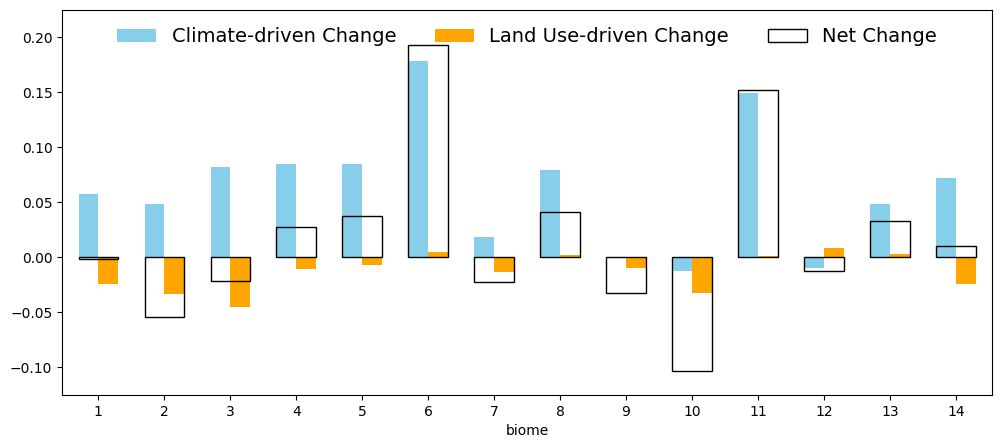

In [13]:
# plot bar chart
plt.figure(figsize=(12, 5))
# tranpose to show biomes on y axis and change to horizontal bars
#(biomeStats['deltaSR']/biomeStats['SR_present']).plot(kind='bar', color='grey', width=0.6, position=0.5)
(biomeStats['deltaSR_clim']/biomeStats['SR_present']).plot(kind='bar', color='skyblue', width=0.3, position=1)
(biomeStats['deltaSR_LU']/biomeStats['SR_present']).plot(kind='bar', color='orange', width=0.3, position=0)
(biomeStats['deltaSR']/biomeStats['SR_present']).plot(kind='bar', fill=False, width=0.6, position=0.5, edgecolor='black', linewidth=1) # outline only, no fill

legend_labels = ['Climate-driven Change', 'Land Use-driven Change', 'Net Change']
# rotate x labels by 45 degrees for better visibility
plt.xticks(rotation=0)
plt.ylim(-0.125, 0.225)
plt.legend(legend_labels, loc='upper center', ncol=3, fontsize=14, frameon=False) # legend icon shape to square

In [ ]:
# relative change: biomes
biome_names = {
    1: 'Tropical and Subtropical\n Moist Broadleaf Forests',
    2: 'Tropical and Subtropical\n Dry Broadleaf Forests',
    3: 'Tropical and Subtropical\n Coniferous Forests',
    4: 'Temperate Broadleaf\n and Mixed Forests',
    5: 'Temperate\n Coniferous Forests',
    6: 'Boreal Forests/Taiga',
    7: 'Tropical and Subtropical\n Grasslands, Savannas,\n and Shrublands',
    8: 'Temperate Grasslands,\n Savannas, and Shrublands',
    9: 'Flooded Grasslands\n and Savannas',
    10: 'Montane Grasslands\n and Shrublands',
    11: 'Tundra',
    12: 'Mediterranean Forests,\n Woodlands, and Scrub',
    13: 'Deserts\n and Xeric Shrublands',
    14: 'Mangroves'
}

fig, ax = plt.subplots(figsize=(6, 12))

y = np.arange(len(biomeStats))
height = 0.25  # bar thickness

ax.barh(y + height/2, biomeStats['deltaSR_clim'] / biomeStats['SR_PI'], 
        height=height, color='violet', label='Climate-driven Change')
ax.barh(y - height/2, biomeStats['deltaSR_LU'] / biomeStats['SR_PI'], 
        height=height, color='tan', label='Land Use-driven Change')
ax.barh(y, biomeStats['deltaSR'] / biomeStats['SR_PI'], 
        height=height * 2, fill=False, hatch = '..', edgecolor='blue', linewidth=1, label='Net Change') # fill with pattern


# Map biome ids to names for tick labels
tick_labels = [biome_names.get(bid, str(bid)) for bid in biomeStats.index]
ax.set_yticks(y)
ax.set_yticklabels(tick_labels, fontsize=14, font=Inter)

ax.set_xlim(-0.125, 0.25)
ax.xtick_labels = ['{:.0f}%'.format(x*100) for x in ax.get_xticks()]
ax.set_xticklabels(ax.xtick_labels, font=Inter) #, fontsize=20
ax.set_xlabel('Change in $S_R$ relative to pre-industrial mean', fontsize=14, font=Inter)
ax.axvline(0, color='black', linewidth=0.8, linestyle='-')  # zero line
ax.legend(ncol=1, fontsize=10, frameon=False, loc='lower right', prop=Inter) #, bbox_to_anchor=(-0.2, -0.12), ) # font: Inter
ax.grid(axis='x', linestyle='--', alpha=0.7)
plt.yticks(fontsize=14),
#plt.tight_layout()
plt.show()
#plt.savefig("../export/biome_bar_chart_horizontal.svg", dpi=300, bbox_inches='tight')

In [ ]:
# mm change: biomes
biome_names = {
    1: 'Tropical and Subtropical\n Moist Broadleaf Forests',
    2: 'Tropical and Subtropical\n Dry Broadleaf Forests',
    3: 'Tropical and Subtropical\n Coniferous Forests',
    4: 'Temperate Broadleaf\n and Mixed Forests',
    5: 'Temperate\n Coniferous Forests',
    6: 'Boreal Forests/Taiga',
    7: 'Tropical and Subtropical\n Grasslands, Savannas,\n and Shrublands',
    8: 'Temperate Grasslands,\n Savannas, and Shrublands',
    9: 'Flooded Grasslands\n and Savannas',
    10: 'Montane Grasslands\n and Shrublands',
    11: 'Tundra',
    12: 'Mediterranean Forests,\n Woodlands, and Scrub',
    13: 'Deserts\n and Xeric Shrublands',
    14: 'Mangroves'
}

fig, ax = plt.subplots(figsize=(6, 12))

y = np.arange(len(biomeStats))
height = 0.25  # bar thickness

ax.barh(y + height/2, biomeStats['deltaSR_clim'], 
        height=height, color='violet', label='Climate-driven Change')
ax.barh(y - height/2, biomeStats['deltaSR_LU'], 
        height=height, color='tan', label='Land Use-driven Change')
ax.barh(y, biomeStats['deltaSR'], 
        height=height * 2, fill=False, hatch = '..', edgecolor='blue', linewidth=1, label='Net Change') # fill with pattern

# Map biome ids to names for tick labels
tick_labels = [biome_names.get(bid, str(bid)) for bid in biomeStats.index]
ax.set_yticks(y)
ax.set_yticklabels(tick_labels, fontsize=16, font=Inter)

ax.set_xlim(-60, 40)
ax.xtick_labels = ['{:.0f}'.format(x) for x in ax.get_xticks()]
ax.set_xticklabels(ax.xtick_labels, fontsize=16, font=Inter)
ax.set_xlabel('Change in mean $S_R$ (mm)', fontsize=14, font=Inter)
ax.axvline(0, color='black', linewidth=0.8, linestyle='-')  # zero line
# ax.legend(ncol=3, fontsize=10, frameon=False, loc='lower left', bbox_to_anchor=(-0.2, -0.12), prop=Inter) # font: Inter
ax.grid(axis='x', linestyle='--', alpha=0.7)
#plt.tight_layout()
plt.show()
#plt.savefig("../export/biome_bar_chart_horizontal.svg", dpi=300, bbox_inches='tight')

In [24]:
biomeStatsVolSum

,SR_present,SR_PI,SR_intact,deltaSR,deltaSR_clim,deltaSR_LU,pct_deltaSR,area
biome,,,,,,,,
1,7205.764763,7050.840971,7196.304273,154.923792,491.823730,-339.930428,83.786953,2.028180e+07
2,1508.872266,1601.875707,1658.324905,-93.003441,73.985846,-174.443912,-18.177611,3.080137e+06
3,363.409825,356.488208,363.432933,6.921616,32.897802,-24.773893,2.322984,7.191724e+05
4,1799.450566,1751.687921,1809.254180,47.762645,127.651021,-72.838809,79.132763,1.306898e+07
5,593.914304,554.590301,557.360998,39.324003,48.294491,-9.654475,47.661907,4.173878e+06
6,818.958461,655.227398,646.528465,163.731063,143.773520,16.553258,365.972749,1.513932e+07
7,7219.965782,7450.237194,7474.909206,-230.271411,15.216429,-270.899183,-43.489924,2.032312e+07
8,971.814980,925.855061,925.677372,45.959919,58.171924,-5.373827,70.625345,1.011410e+07
9,315.311596,337.846072,336.472157,-22.534476,-17.046891,-8.356716,-1.324895,1.100405e+06


In [ ]:
# volume changes: biomes
fig, ax = plt.subplots(figsize=(6, 12))
plt.rcParams.update({'font.size': 14})

y = np.arange(len(biomeStatsVol))
height = 0.25  # bar thickness

ax.barh(y + height/2, biomeStatsVolSum['deltaSR_clim'], 
        height=height, color='violet', label='Climate-driven')
ax.barh(y - height/2, biomeStatsVolSum['deltaSR_LU'], 
        height=height, color='tan', label='Land Use-driven')
ax.barh(y, biomeStatsVolSum['deltaSR'], 
        height=height * 2, fill=False, hatch = '..', edgecolor='blue', linewidth=1, label='Total') # fill with pattern

# Map biome ids to names for tick labels
tick_labels = [biome_names.get(bid, str(bid)) for bid in biomeStatsVol.index]
ax.set_yticks(y)
ax.set_yticklabels(tick_labels, fontsize=16, font=Inter)

ax.set_xlim(-380, 520)
#ax.set_xscale('symlog', linthresh=10)
ax.xtick_labels = ['{:.0f}'.format(x) for x in ax.get_xticks()]
ax.set_xticklabels(ax.xtick_labels, fontsize=20, font=Inter)
# x ticklabels line spacing reduced
plt.setp(ax.get_xticklabels(), linespacing=0.5)
ax.set_xlabel('Change in $S_R$ volume (km³)', fontsize=14, font=Inter)
ax.axvline(0, color='black', linewidth=0.8, linestyle='-')  # zero line
#ax.legend(ncol=3, fontsize=10, frameon=False, loc='lower left', bbox_to_anchor=(-0.2, -0.12), prop=Inter) # font: Inter
# ax.legend(ncol=1, fontsize=8, frameon=False, loc='upper right', prop=Inter) # bbox_to_anchor=(-0.2, -0.12)
ax.grid(axis='x', linestyle='--', alpha=0.7)
#plt.tight_layout()
plt.yticks(fontsize=14),
plt.show()
#plt.savefig("../export/biome_bar_chart_horizontal.svg", dpi=300, bbox_inches='tight')

In [ ]:
# plot maps of specific biomes
plot_map(deltaSR.where(biome==1), title='Change in $S_R$ in Tropical and Subtropical Moist Broadleaf Forests', cmap='BrBG', vmin=-50, vmax=50, borders=False, cbar_label='Change in $S_R$ (mm)', grid_labels=True)
plot_map(deltaSR_clim.where(biome==1), title='Climate-driven Change in $S_R$ in Tropical and Subtropical Moist Broadleaf Forests', cmap='BrBG', vmin=-50, vmax=50, borders=False, cbar_label='Change in $S_R$ (mm)', grid_labels=True)
plot_map(deltaSR_LU.where(biome==1), title='Land Use-driven Change in $S_R$ in Tropical and Subtropical Moist Broadleaf Forests', cmap='BrBG', vmin=-50, vmax=50, borders=False, cbar_label='Change in $S_R$ (mm)', grid_labels=True)

In [ ]:
# plot maps of specific biomes
plot_map(deltaSR.where(biome==10), title='Change in $S_R$ in Montane Grasslands', cmap='BrBG', vmin=-50, vmax=50, borders=False, cbar_label='Change in $S_R$ (mm)', grid_labels=True)
plot_map(deltaSR_clim.where(biome==10), title='Climate-driven Change in $S_R$ in Montane Grasslands', cmap='BrBG', vmin=-50, vmax=50, borders=False, cbar_label='Change in $S_R$ (mm)', grid_labels=True)
plot_map(deltaSR_LU.where(biome==10), title='Land Use-driven Change in $S_R$ in Montane Grasslands', cmap='BrBG', vmin=-50, vmax=50, borders=False, cbar_label='Change in $S_R$ (mm)', grid_labels=True)

In [10]:
# global means using the global_stats function
deltaSR_mean, deltaSR_std = global_stats(deltaSR, weighted=True)
deltaSR_clim_mean, deltaSR_clim_std = global_stats(deltaSR_clim, weighted=True)
deltaSR_LU_mean, deltaSR_LU_std = global_stats(deltaSR_LU, weighted=True)
deltaSR_interaction_mean, deltaSR_interaction_std = global_stats(deltaSR_interaction, weighted=True)

# print the results
print(f"Total change in SR (1991-2020 vs Pre-industrial): {deltaSR_mean:.2f}")
print(f"Change in SR due to climate (1991-2020 vs 1901-1930): {deltaSR_clim_mean:.2f}")
print(f"Change in SR due to land use (1991-2020 vs Pre-industrial): {deltaSR_LU_mean:.2f}")
print(f"Interaction effect on SR (1991-2020 vs 1901-1930): {deltaSR_interaction_mean:.2f}")

Total change in SR (1991-2020 vs Pre-industrial): 6.76
Change in SR due to climate (1991-2020 vs 1901-1930): 9.97
Change in SR due to land use (1991-2020 vs Pre-industrial): -3.68
Interaction effect on SR (1991-2020 vs 1901-1930): 0.48


In [103]:
np.linspace(-150 - (150/15), 150 + (150/15), int((15+1)/2)+1)

array([-160., -120.,  -80.,  -40.,    0.,   40.,   80.,  120.,  160.])

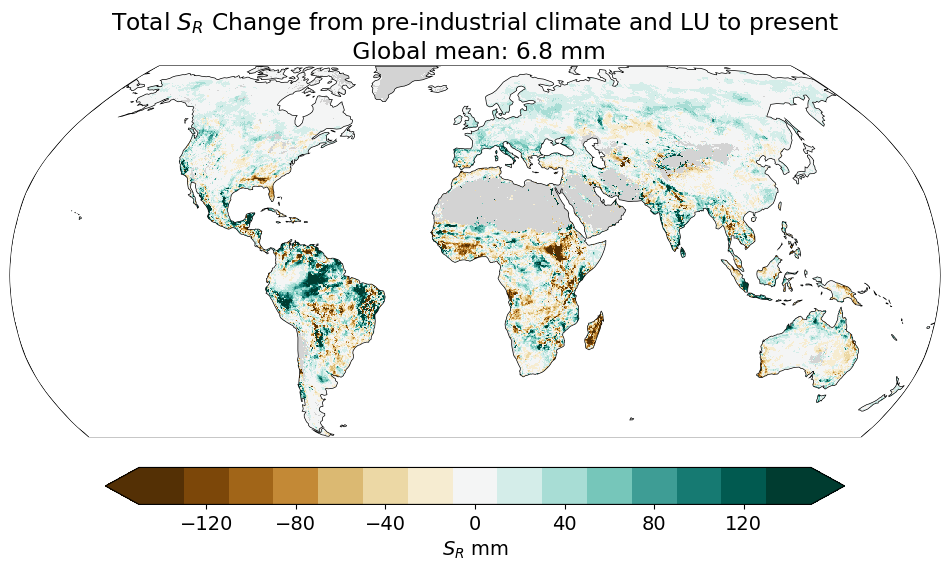

In [11]:
plt.rcParams.update({'font.size': 14})
plot_map(deltaSR.coarsen(dim={'lat': 5, 'lon': 5}).median(), title=f'Total $S_R$ Change from pre-industrial climate and LU to present \n Global mean: {deltaSR_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label='$S_R$ mm')

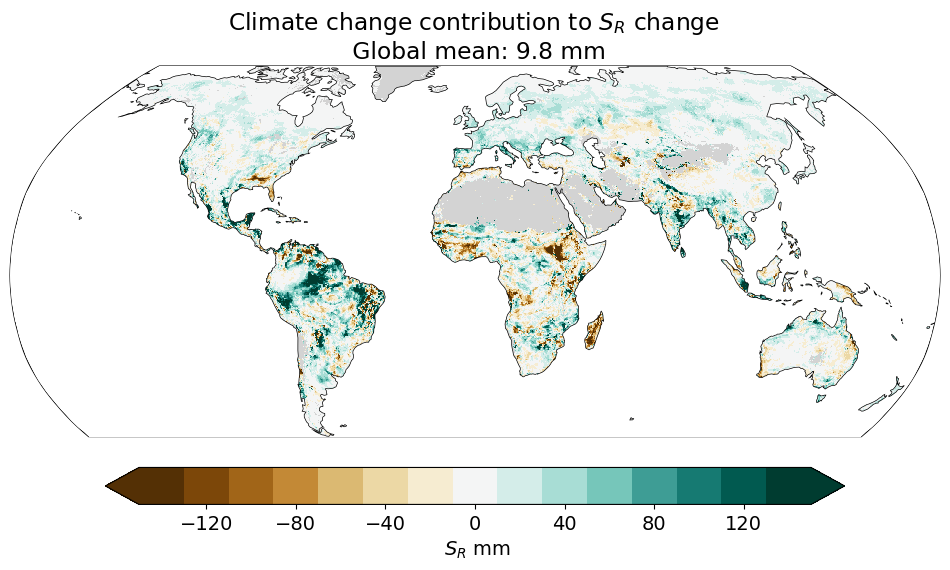

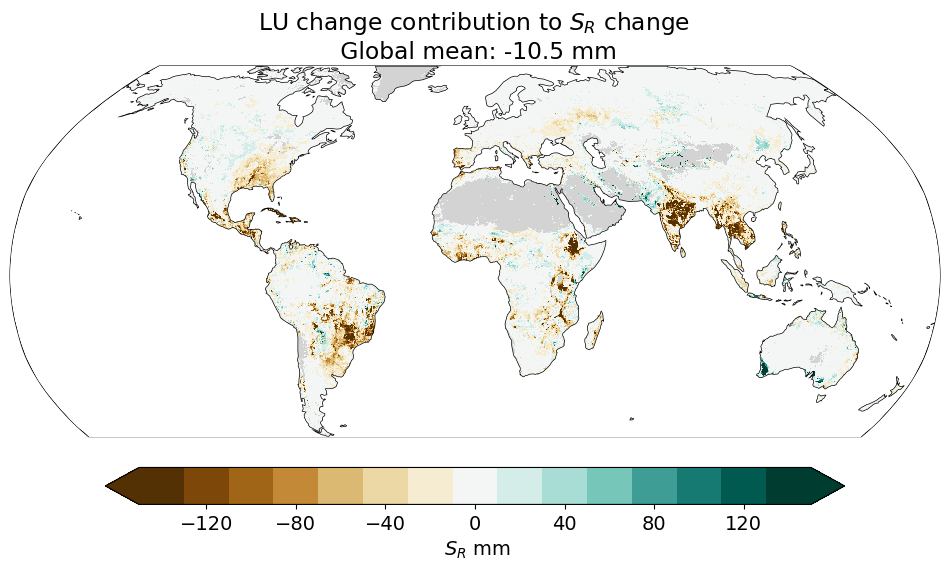

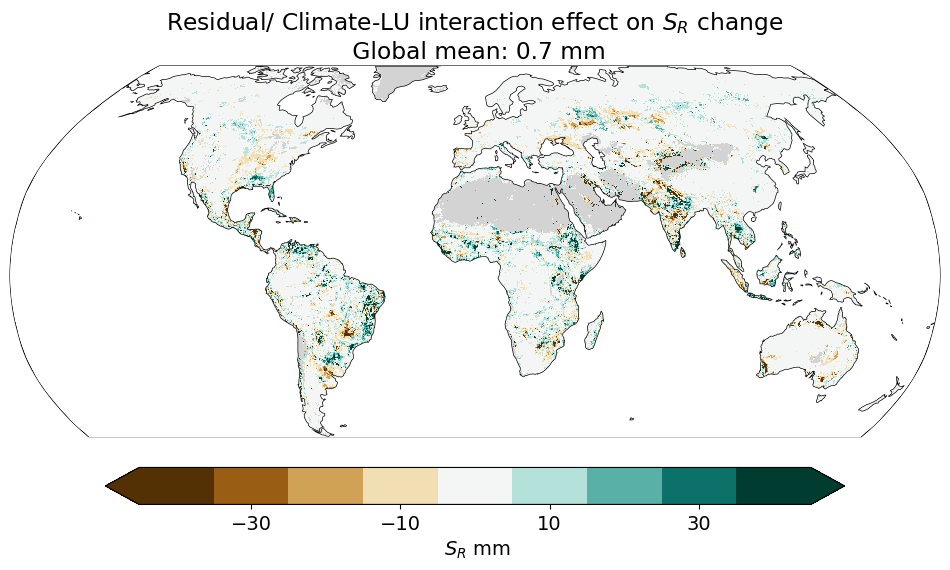

In [107]:
plt.rcParams.update({'font.size': 14})
plot_map(deltaSR_clim.coarsen(dim={'lat': 5, 'lon': 5}).median(), title=f'Climate change contribution to $S_R$ change \n Global mean: {deltaSR_clim_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')
plot_map(deltaSR_LU.coarsen(dim={'lat': 5, 'lon': 5}).median(), title=f'LU change contribution to $S_R$ change \n Global mean: {deltaSR_LU_mean:.1f} mm', cmap='BrBG', discrete_cmap = 15, vmin=-150, vmax=150, borders=False, cbar_label=' $S_R$ mm')
plot_map(deltaSR_interaction.coarsen(dim={'lat': 5, 'lon': 5}).median(), title=f'Residual/ Climate-LU interaction effect on $S_R$ change\n Global mean: {deltaSR_interaction_mean:.1f} mm', cmap='BrBG', discrete_cmap = 9, vmin=-45, vmax=45, borders=False, cbar_label=' $S_R$ mm')

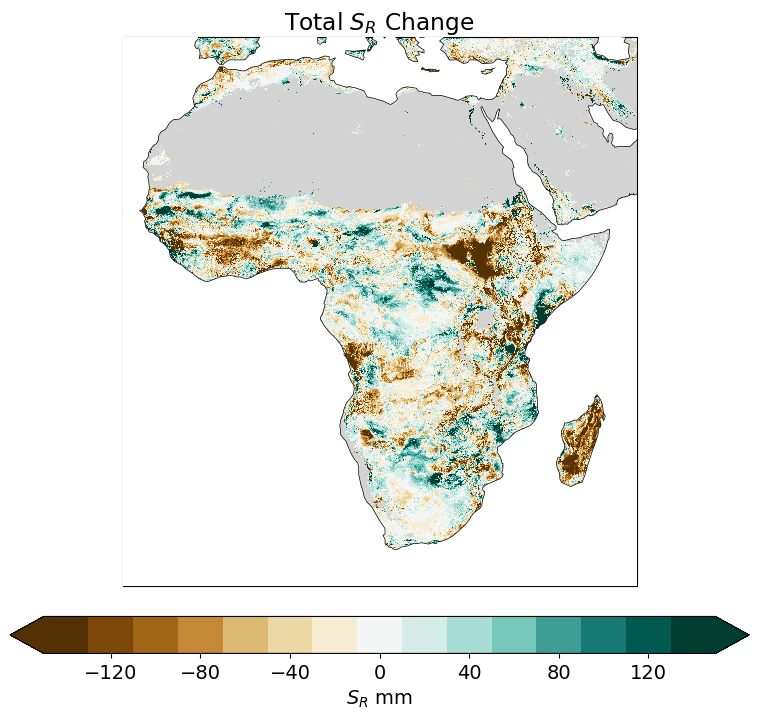

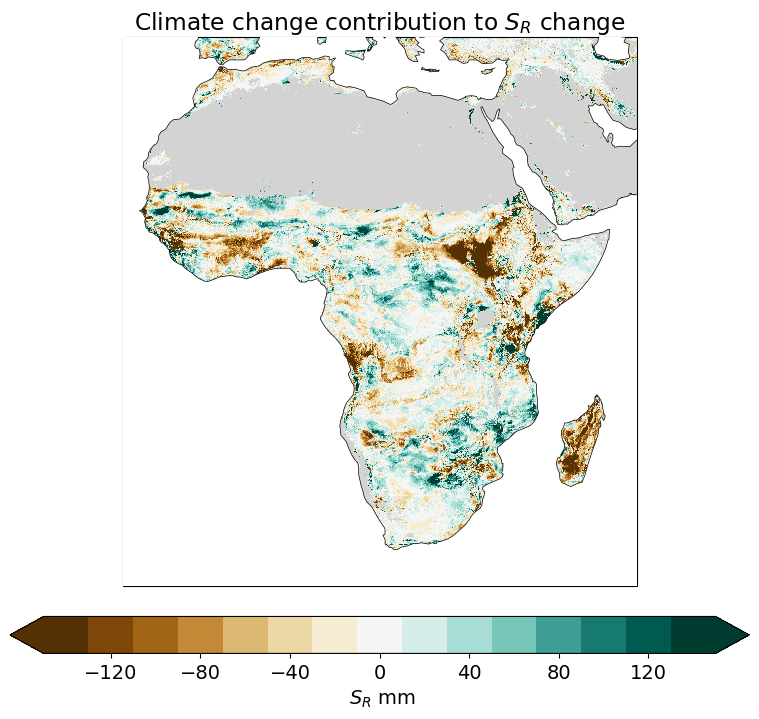

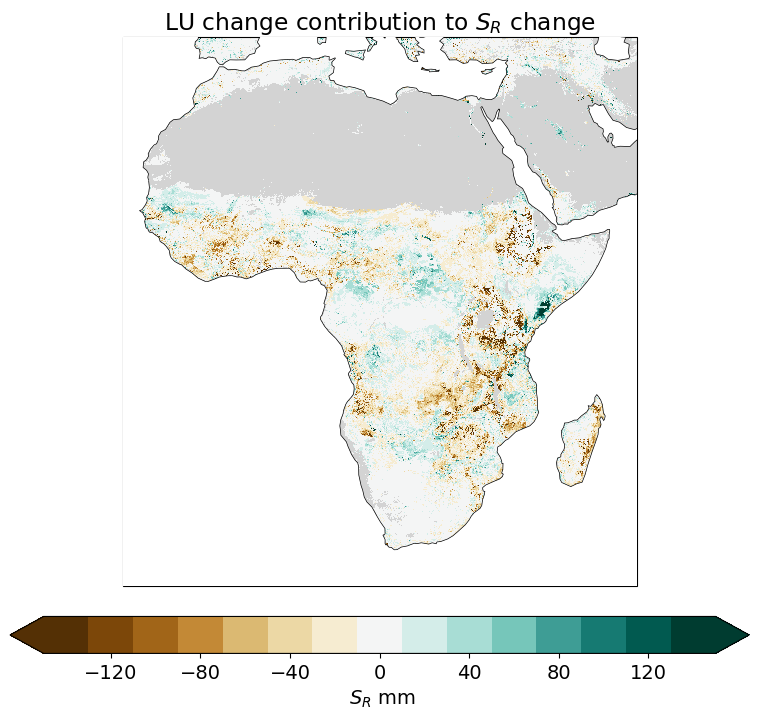

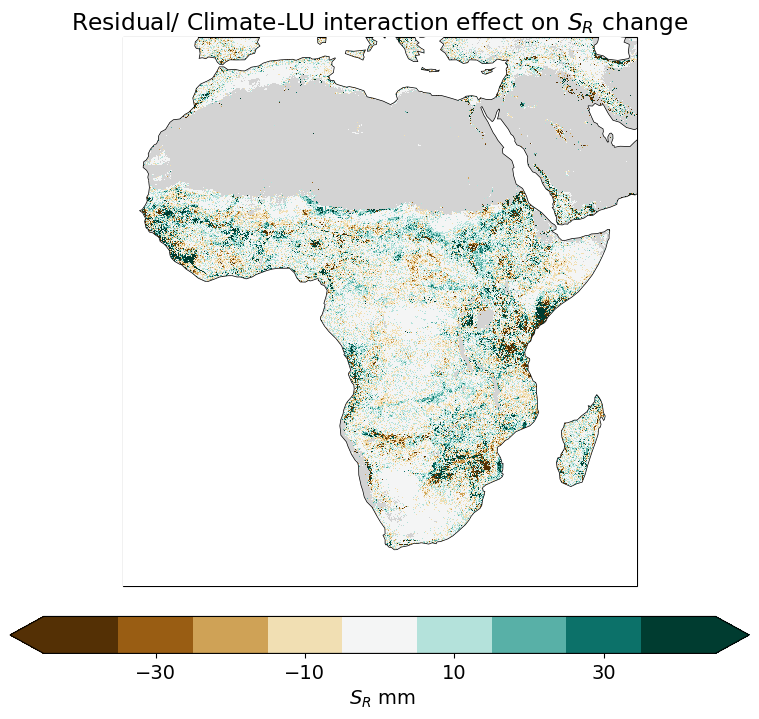

In [24]:
# africa maps
plot_map(deltaSR.sel(lat=slice(-40, 40), lon=slice(-20, 55)),
         local_map=True, vmin=-150, vmax=150, cmap='BrBG', discrete_cmap = 15,
         title='Total $S_R$ Change',
         borders=False, cbar_label='$S_R$ mm')
plot_map(deltaSR_clim.sel(lat=slice(-40, 40), lon=slice(-20, 55)),
         local_map=True, vmin=-150, vmax=150, cmap='BrBG', discrete_cmap = 15,
         title='Climate change contribution to $S_R$ change',
         borders=False, cbar_label=' $S_R$ mm')
plot_map(deltaSR_LU.sel(lat=slice(-40, 40), lon=slice(-20, 55)),
         local_map=True, vmin=-150, vmax=150, cmap='BrBG', discrete_cmap = 15,
         title='LU change contribution to $S_R$ change',
         borders=False, cbar_label=' $S_R$ mm')
plot_map(deltaSR_interaction.sel(lat=slice(-40, 40), lon=slice(-20, 55)),
        local_map=True, vmin=-45, vmax=45, cmap='BrBG', discrete_cmap = 9,
        title='Residual/ Climate-LU interaction effect on $S_R$ change',
        borders=False, cbar_label=' $S_R$ mm')

In [110]:
# percentage of valid cells where both climate and LU change have the same sign as the total change
synergistic_change = ((deltaSR_clim * deltaSR_LU) > 0) & deltaSR.notnull()
percentage_synergistic = synergistic_change.sum().item() / deltaSR.notnull().sum().item() * 100
print(f"Percentage of valid cells where climate and LU change have the same sign as the total change: {percentage_synergistic:.1f}%")

Percentage of valid cells where climate and LU change have the same sign as the total change: 49.8%


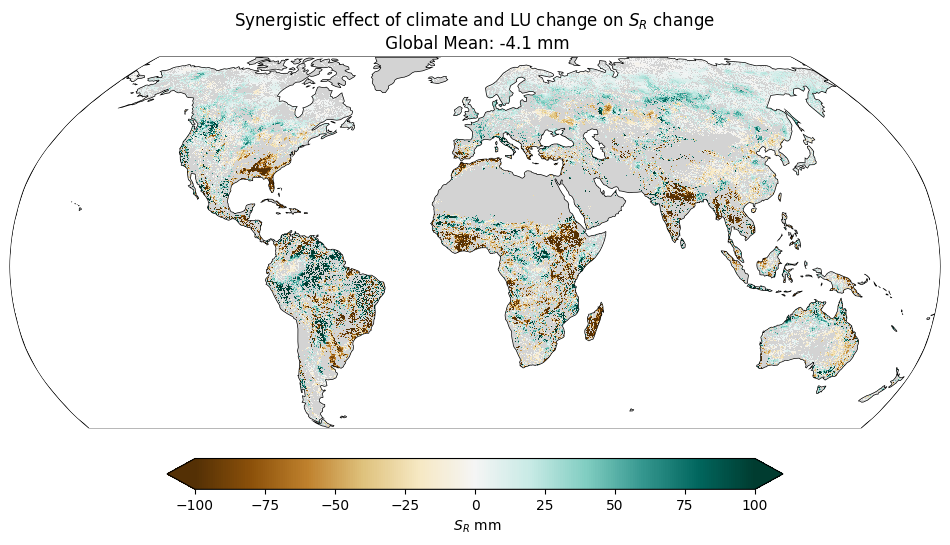

In [21]:
# synergistic effect of climate and LU
# map delta SR where both climate and LU effect are same sign
plot_map(deltaSR.where(synergistic_change), title=f'Synergistic effect of climate and LU change on $S_R$ change \n Global Mean: {global_stats(deltaSR.where(synergistic_change))[0].item():.1f} mm', cmap='BrBG', vmin=-100, vmax=100, borders=False, cbar_label=' $S_R$ mm')

In [109]:
lu_dominant = (np.abs(deltaSR_LU) > np.abs(deltaSR_clim)) & deltaSR.notnull()

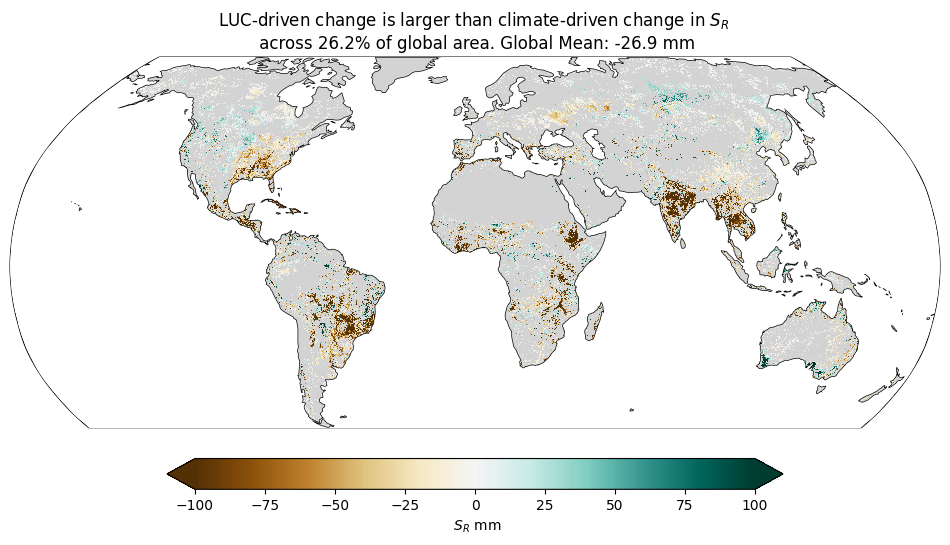

In [29]:
# plot delta SR where lu_dominant
plot_map(deltaSR.where(lu_dominant), title=f'LUC-driven change is larger than climate-driven change in $S_R$ \n across {lu_dominant.sum() * 100 / deltaSR.notnull().sum():.1f}% of global area. Global Mean: {global_stats(deltaSR.where(lu_dominant))[0].item():.1f} mm', cmap='BrBG', vmin=-100, vmax=100, borders=False, cbar_label=' $S_R$ mm')

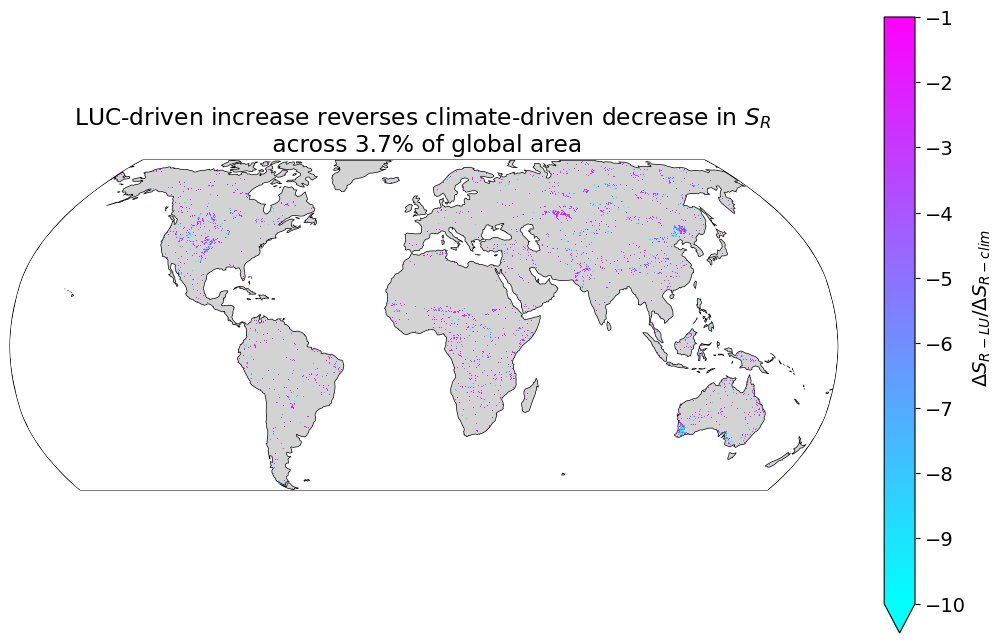

In [108]:
# LUC-driven increase reverses climate-driven decrease
lu_dominant_increase = (deltaSR_LU * deltaSR_clim < 0) & (abs(deltaSR_LU) > abs(deltaSR_clim)) & (deltaSR_LU > 0)
plot_map((deltaSR_LU / deltaSR_clim).where(lu_dominant_increase), title=f'LUC-driven increase reverses climate-driven decrease in $S_R$ \n across {lu_dominant_increase.sum() * 100 / deltaSR.notnull().sum():.1f}% of global area', cmap='cool', vmin=-10, vmax=-1, cbar_loc='right', cbar_label=' $ΔS_{R-LU}/ΔS_{R-clim}$')

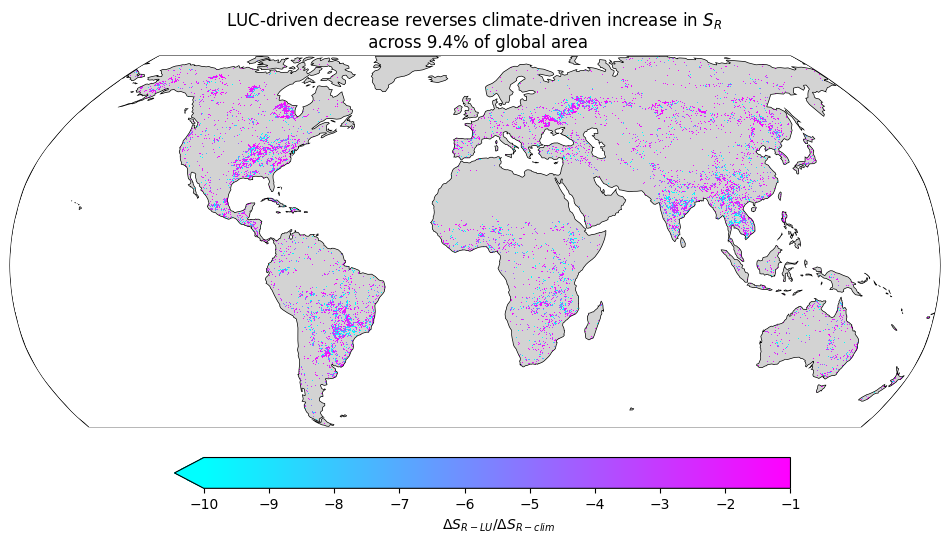

In [25]:
# LUC driven decrease dominates climate-driven increase
lu_dominant_decrease = (deltaSR_LU * deltaSR_clim < 0) & (abs(deltaSR_LU) > abs(deltaSR_clim)) & (deltaSR_LU < 0)
plot_map((deltaSR_LU / deltaSR_clim).where(lu_dominant_decrease), title=f'LUC-driven decrease reverses climate-driven increase in $S_R$ \n across {lu_dominant_decrease.sum() * 100 / deltaSR.notnull().sum():.1f}% of global area', cmap='cool', vmin = -10, vmax=-1, borders=False, cbar_label=' $ΔS_{R-LU}/ΔS_{R-clim}$')

In [28]:
print('LU-dominant areas: {:.1f}%'.format(lu_dominant.sum() * 100 / deltaSR.notnull().sum()))
print('LU-dominant increases: {:.1f}%'.format(lu_dominant_increase.sum() * 100 / deltaSR.notnull().sum()))
print('LU-dominant decreases: {:.1f}%'.format(lu_dominant_decrease.sum() * 100 / deltaSR.notnull().sum()))

LU-dominant areas: 26.2%
LU-dominant increases: 3.7%
LU-dominant decreases: 9.4%


In [ ]:
# Is error and decomposition residual (interaction) correlated? 
# Scatter plot of error vs interaction effect, with a line of best fit and correlation coefficient
from scipy.stats import pearsonr
# mutually mask the two arrays to ensure we only compare valid data points
valid_mask = np.isfinite(error) & np.isfinite(deltaSR_interaction)
error_valid = error.where(valid_mask, drop=True)
interaction_valid = deltaSR_interaction.where(valid_mask, drop=True)
error_flat = error_valid.values.flatten()
interaction_flat = interaction_valid.values.flatten()
error_flat = error_flat[~np.isnan(error_flat)] # remove any remaining NaNs
interaction_flat = interaction_flat[~np.isnan(interaction_flat)] # remove any remaining NaNs

# correaltion between absolute error and absolute interaction effect
abs_error_flat = np.abs(error_flat)
abs_interaction_flat = np.abs(interaction_flat)
corr, p_value = pearsonr(abs_error_flat, abs_interaction_flat)
print(f"Correlation between absolute error and absolute interaction effect: {corr:.2f} (p-value: {p_value:.2e})")

# correlation between error and interaction log values
log_abs_error_flat = np.log(np.abs(error_flat) + 1) # add 1 to avoid log(0)
log_abs_interaction_flat = np.log(np.abs(interaction_flat) + 1) # add 1 to avoid log(0)
corr_log, p_value_log = pearsonr(log_abs_error_flat, log_abs_interaction_flat)
print(f"Correlation between log absolute error and log absolute interaction effect: {corr_log:.2f} (p-value: {p_value_log:.2e})")

plt.figure(figsize=(8, 6))
plt.scatter(interaction_flat, error_flat, alpha=0.5, s=1)
plt.xlabel('Climate-LU Interaction Effect on SR (mm)')
plt.ylabel('Prediction Error (mm)')
plt.xlim(-1500, 5000)
plt.ylim(-2500, 3000)
plt.title('Prediction Error vs Climate-LU Interaction Effect')
# line of best fit
m, b = np.polyfit(interaction_flat, error_flat, 1)
plt.plot(interaction_flat, m*interaction_flat + b, color='red')
# correlation coefficient
corr_coef, p_value = pearsonr(interaction_flat, error_flat)
print(f"Pearson correlation coefficient: {corr_coef:.2f}, p-value: {p_value:.2e}")
plt.show()

# plot log values of absolute error and absolute interaction effect
plt.figure(figsize=(8, 6))
plt.scatter(log_abs_interaction_flat, log_abs_error_flat, alpha=0.5, s=1)
plt.xlabel('Log of Absolute Climate-LU Interaction Effect on SR')
plt.ylabel('Log of Absolute Prediction Error (mm)')
plt.title('Log of Prediction Error vs Log of Climate-LU Interaction Effect')
# line of best fit
m_log, b_log = np.polyfit(log_abs_interaction_flat, log_abs_error_flat, 1)
plt.plot(log_abs_interaction_flat, m_log*log_abs_interaction_flat + b_log, color='red')
# correlation coefficient
corr_log, p_value_log = pearsonr(log_abs_interaction_flat, log_abs_error_flat)
print(f"Correlation between log absolute error and log absolute interaction effect: {corr_log:.2f} (p-value: {p_value_log:.2e})")
plt.show()

Correlation between absolute error and absolute interaction effect: 0.39 (p-value: 0.00e+00)
Correlation between log absolute error and log absolute interaction effect: 0.47 (p-value: 0.00e+00)


In [ ]:
import matplotlib.pyplot as plt
from pyfonts import load_google_font

#font = load_font('../fonts/InterVariable.ttf')
noto_font = load_google_font("Noto Sans")
OpenSans = load_google_font("Open Sans")
Inter = load_google_font("Inter")

fig, ax = plt.subplots()
ax.text(
x=0.2,
y=0.5,
s="Hey there!",
size=30,
font=Inter # We pass it to the `font` argument
)

In [24]:
# reset rc params to default
plt.rcParams.update(plt.rcParamsDefault)

In [ ]:
#plt.rcParams['font.family'] = 'Inter'
plt.figure(figsize=(14, 6))
ax = plt.axes(projection=ccrs.PlateCarree()) # or robinson
daPlot = deltaSR.coarsen(lat=5, lon=5).median() # coarsen for faster plotting
# 1. Plot only nans in grey (suppress cbar)
xr.where(daPlot.isnull(), 1, np.nan).plot(
    ax=ax, 
    cmap=colors.ListedColormap(['lightgrey']), 
    vmin=1, 
    vmax=1, 
    transform=ccrs.PlateCarree(), 
    add_colorbar=False
)
#Plot ovean over nans in white
ocean.coarsen(lat=5, lon=5).mean().plot(
    ax=ax, 
    cmap=colors.ListedColormap(['white']),
    vmin=1,
    vmax=1,
    transform=ccrs.PlateCarree(),
    add_colorbar=False
)

# 2. Plot data (store the plot object as 'im' and suppress automatic cbar)
im = daPlot.plot(
    ax=ax, 
    cmap=discrete_colormap('BrBG', 8), 
    vmin=-160, 
    vmax=160, 
    transform=ccrs.PlateCarree(), 
    add_colorbar=False
)

# 3. Create a dedicated axis for the horizontal colorbar below the plot
# Adjust the bottom positioning (0.05) so it doesn't overlap with the latitude labels
cax = plt.gcf().add_axes([0.25, 0.05, 0.5, 0.03]) # [left, bottom, width, height]

# 4. Generate the colorbar horizontally with explicit boundary ticks.
# control width and height of colorbar with cax, and set ticks to match the discrete colormap boundaries
cbar = plt.colorbar(
    im, 
    cax=cax, 
    orientation='horizontal', 
    #fraction=1,
    aspect=30,
    ticks=[-160, -120, -80, -40, 0, 40, 80, 120, 160],
    extend='both',
    pad=0.02

)
cbar.set_label('$S_R$ (mm)', size=12)
cbar.ax.tick_params(labelsize=10)

# 5. Add context features
ax.coastlines(linewidth=0.5) # coastlines for context

# 6. Gridlines configuration
lon_ticks = [-180, -120, -60, 0, 60, 120, 180]
lat_ticks = [-45, -30, -15, 0, 15, 30, 45]
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0,
    x_inline=False,
    y_inline=False,
)

# Show only bottom and left labels
gl.top_labels = False
gl.right_labels = False
gl.bottom_labels = True
gl.left_labels = True
gl.xlocator = FixedLocator(lon_ticks)
gl.ylocator = FixedLocator(lat_ticks)
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}

ax.set_title(f'Total $S_R$ Change from pre-industrial climate and LU to present \n Global mean: {deltaSR_mean:.1f} mm', font=Inter, fontsize=16)
#plt.savefig("../export/map_deltaSRmm.png", format='png', dpi=300, bbox_inches='tight')
plt.show()

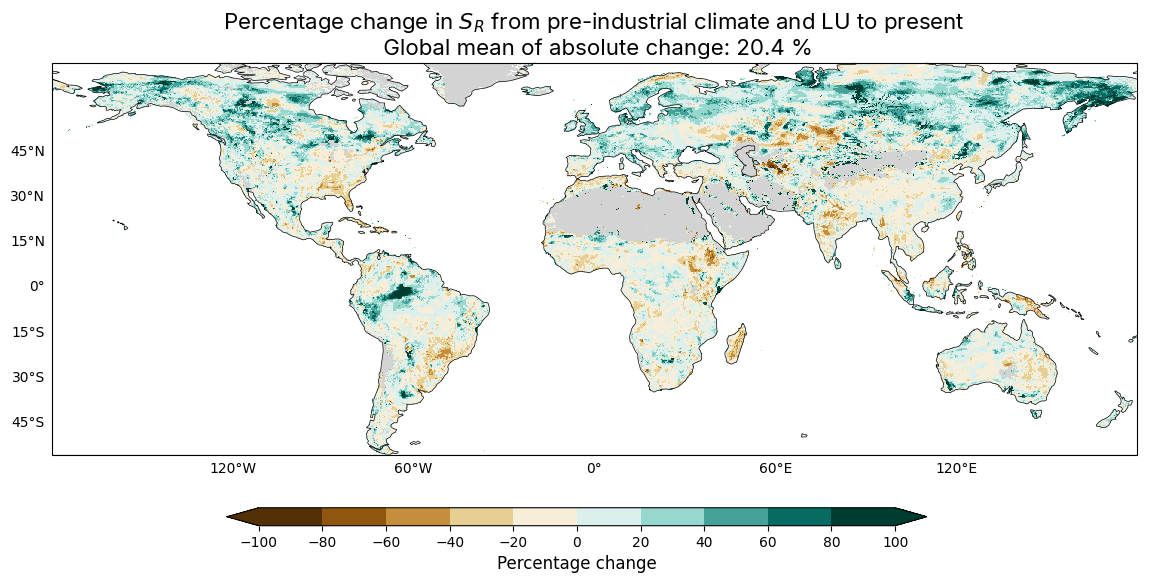

In [113]:
#plt.rcParams['font.family'] = 'Inter'
plt.figure(figsize=(14, 6))
ax = plt.axes(projection=ccrs.PlateCarree()) # or robinson
daPlot = pct_deltaSR.coarsen(lat=5, lon=5).median() # coarsen for faster plotting
# 1. Plot only nans in grey (suppress cbar)
xr.where(daPlot.isnull(), 1, np.nan).plot(
    ax=ax, 
    cmap=colors.ListedColormap(['lightgrey']), 
    vmin=1, 
    vmax=1, 
    transform=ccrs.PlateCarree(), 
    add_colorbar=False
)
#Plot ovean over nans in white
ocean.coarsen(lat=5, lon=5).mean().plot(
    ax=ax, 
    cmap=colors.ListedColormap(['white']),
    vmin=1,
    vmax=1,
    transform=ccrs.PlateCarree(),
    add_colorbar=False
)

# 2. Plot data (store the plot object as 'im' and suppress automatic cbar)
im = daPlot.plot(
    ax=ax, 
    cmap=discrete_colormap('BrBG', 10), 
    vmin=-100, 
    vmax=100, 
    transform=ccrs.PlateCarree(), 
    add_colorbar=False
)

# 3. Create a dedicated axis for the horizontal colorbar below the plot
# Adjust the bottom positioning (0.05) so it doesn't overlap with the latitude labels
cax = plt.gcf().add_axes([0.25, 0.05, 0.5, 0.03]) # [left, bottom, width, height]

# 4. Generate the colorbar horizontally with explicit boundary ticks.
# control width and height of colorbar with cax, and set ticks to match the discrete colormap boundaries
cbar = plt.colorbar(
    im, 
    cax=cax, 
    orientation='horizontal', 
    #fraction=1,
    aspect=30,
    ticks=[-100, -80, -60, -40, -20, 0, 20, 40, 60, 80, 100],
    extend='both',
    pad=0.02

)
cbar.set_label('Percentage change', size=12)
cbar.ax.tick_params(labelsize=10)

# 5. Add context features
ax.coastlines(linewidth=0.5) # coastlines for context

# 6. Gridlines configuration
lon_ticks = [-180, -120, -60, 0, 60, 120, 180]
lat_ticks = [-45, -30, -15, 0, 15, 30, 45]
gl = ax.gridlines(
    crs=ccrs.PlateCarree(),
    draw_labels=True,
    linewidth=0,
    x_inline=False,
    y_inline=False,
)

# Show only bottom and left labels
gl.top_labels = False
gl.right_labels = False
gl.bottom_labels = True
gl.left_labels = True
gl.xlocator = FixedLocator(lon_ticks)
gl.ylocator = FixedLocator(lat_ticks)
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()
gl.xlabel_style = {'size': 10}
gl.ylabel_style = {'size': 10}

abs_pct_deltaSR_mean = global_stats(abs_pct_deltaSR, weighted=True)[0]
ax.set_title(f'Percentage change in $S_R$ from pre-industrial climate and LU to present \n Global mean of absolute change: {abs_pct_deltaSR_mean:.1f} %', font=Inter, fontsize=16)
#plt.savefig("../export/map_deltaSRmm.png", format='png', dpi=300, bbox_inches='tight')
plt.show()

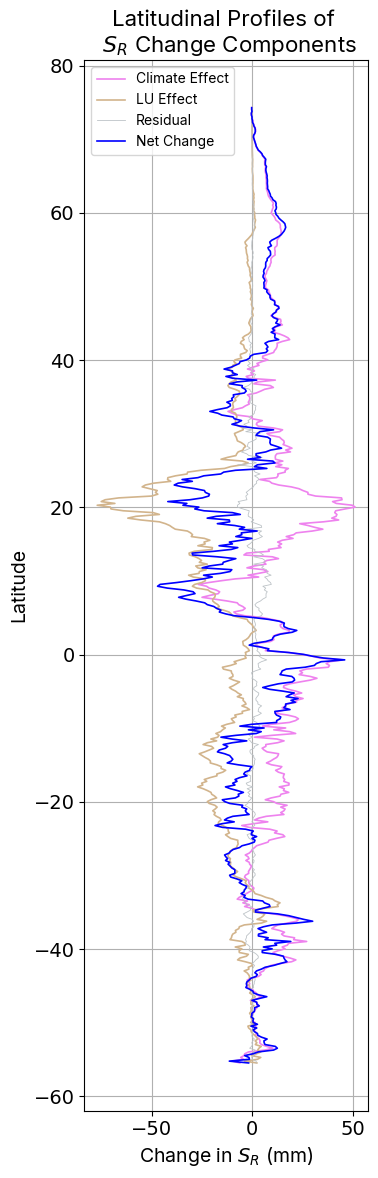

In [49]:
# Plot latitudinal profiles of the deltaSR components
# average across longitude to get latitudinal profiles
# and then plot them on the same plot with different colors for each component.

deltaSRclim_plot = deltaSR_clim.coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile
deltaSR_LU_plot = deltaSR_LU.coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile
deltaSR_interaction_plot = deltaSR_interaction.coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile
deltaSR_plot = deltaSR.coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile

c_total = 'blue'# "#292929"
c_clim  = 'violet' #'#2980b9'
c_lu    = 'tan' #"#cf584b"
c_int   = '#bdc3c7'
plt.rcParams.update({'font.size': 14})
fig, ax = plt.subplots(figsize=(4, 12))
ax.plot(deltaSRclim_plot.mean(dim='lon'), deltaSRclim_plot['lat'], label='Climate Effect', color=c_clim, linewidth=1.2)
ax.plot(deltaSR_LU_plot.mean(dim='lon'), deltaSR_LU_plot['lat'], label='LU Effect', color=c_lu, linewidth=1.2)
ax.plot(deltaSR_interaction_plot.mean(dim='lon'), deltaSR_interaction_plot['lat'], label='Residual', color=c_int, linewidth=0.6)
ax.plot(deltaSR_plot.mean(dim='lon'), deltaSR_plot['lat'], label='Net Change', color=c_total, linewidth=1.2)
ax.set_xlabel('Change in $S_R$ (mm)', font = Inter, fontsize=14)
ax.set_ylabel('Latitude', font = Inter, fontsize=14)
ax.set_title('Latitudinal Profiles of \n $S_R$ Change Components', font = Inter, fontsize=16)
ax.legend(loc='upper left', frameon=True, fontsize=12, prop=Inter) #, bbox_to_anchor=(0.5, 1.2))
ax.grid()
#plt.savefig("../export/latitudinal_profiles.svg", format='svg', bbox_inches='tight')
plt.tight_layout()
plt.show()

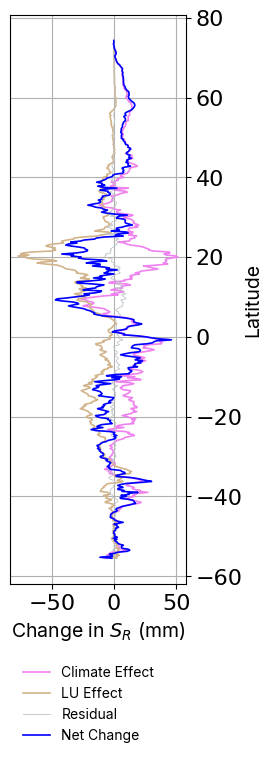

In [121]:
# Plot latitudinal profiles of the deltaSR components
# average across longitude to get latitudinal profiles
# and then plot them on the same plot with different colors for each component.

deltaSRclim_plot = deltaSR_clim.coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile
deltaSR_LU_plot = deltaSR_LU.coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile
deltaSR_interaction_plot = deltaSR_interaction.coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile
deltaSR_plot = deltaSR.coarsen(lon=5, lat =5, boundary='trim').mean() # coarsen to smooth the profile

c_total = 'blue'# "#292929"
c_clim  = 'violet' #'#2980b9'
c_lu    = 'tan' #"#cf584b"
c_int   = '#bdc3c7'
plt.rcParams.update({'font.size': 16})
fig, ax = plt.subplots(figsize=(3, 8))
# change y axis to right side and move the labels to the right as well
ax.yaxis.tick_right()
ax.yaxis.set_label_position('right')
# reduce y axis label padding
ax.yaxis.labelpad = 1
ax.plot(deltaSRclim_plot.mean(dim='lon'), deltaSRclim_plot['lat'], label='Climate Effect', color=c_clim, linewidth=1.2)
ax.plot(deltaSR_LU_plot.mean(dim='lon'), deltaSR_LU_plot['lat'], label='LU Effect', color=c_lu, linewidth=1.2)
ax.plot(deltaSR_interaction_plot.mean(dim='lon'), deltaSR_interaction_plot['lat'], label='Residual', color=c_int, linewidth=0.6)
ax.plot(deltaSR_plot.mean(dim='lon'), deltaSR_plot['lat'], label='Net Change', color=c_total, linewidth=1.2)
ax.set_xlabel('Change in $S_R$ (mm)', font = Inter, fontsize=14)
ax.set_ylabel('Latitude', font = Inter, fontsize=14)
#ax.set_title('Latitudinal Profiles of \n $S_R$ Change Components', font = Inter, fontsize=16)
ax.legend(loc='lower left', frameon=False, fontsize=14, prop=Inter, bbox_to_anchor=(0, -0.3))
ax.grid()
#plt.savefig("../export/latitudinal_profiles.svg", format='svg', bbox_inches='tight')
plt.tight_layout()
plt.show()

In [7]:
sr_clim_1961_1990_LU_1961_1990 = preds.sel(climate='1961_1990', lu='1961_1990').sr_k6_mean
deltaSR_recent = sr_clim_1991_2020_LU_1991_2020 - sr_clim_1961_1990_LU_1961_1990
deltaSR_recent_mean, deltaSR_recent_std = global_stats(deltaSR_recent, weighted=True)
print(f"Change in SR (1991-2020 vs 1961-1990): {deltaSR_recent_mean:.2f} mm")

Change in SR (1991-2020 vs 1961-1990): 7.35 mm


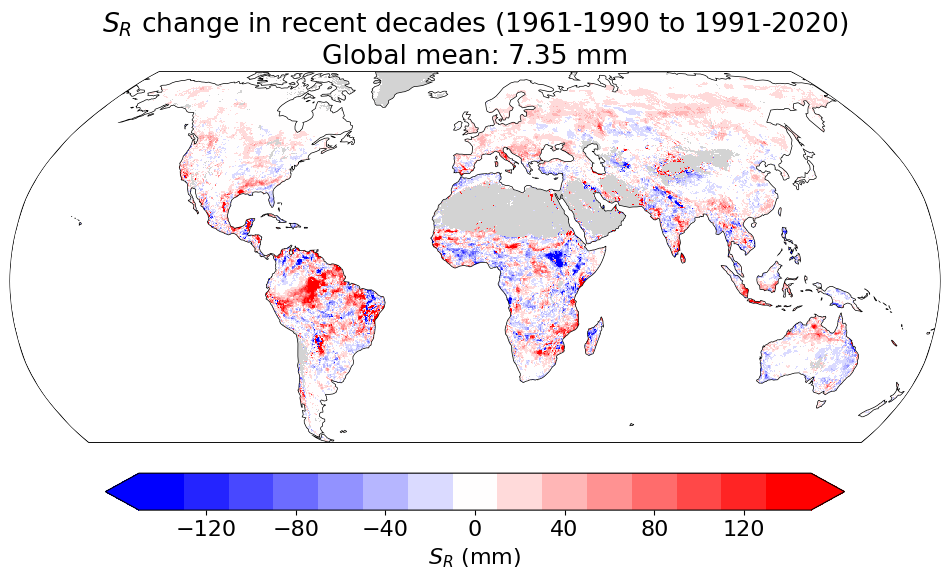

In [8]:
plt.rcParams.update({'font.size': 16})
plot_map(deltaSR_recent.coarsen(lat=5, lon=5).median(), title=f'$S_R$ change in recent decades (1961-1990 to 1991-2020)\nGlobal mean: {deltaSR_recent_mean:.2f} mm', cmap='bwr', vmin=-150, vmax=150, discrete_cmap=15, cbar_label='$S_R$ (mm)')

In [ ]:
# zoom-in: Australia
plot_map(deltaSR_recent.sel(lat=slice(-45, -10), lon=slice(110, 155)), title=f'$S_R$ change in recent decades (1961-1990 to 1991-2020)', cmap='coolwarm', vmin=-100, vmax=100, borders=False, cbar_label='$S_R$ (mm)', local_map=True)

In [ ]:
# sr_clim_1961_1990_LU_1961_1990.drop_vars(['climate', 'lu']).rename('sr').to_netcdf("../export/sr_1961_1990.nc")

In [16]:
sr_clim_2071_2099_ssp460_LU_2071_2099_ssp460 = preds.sel(climate='2071_2099_ssp460', lu='2071_2099_ssp460').sr_k6_mean
sr_clim_2071_2099_ssp370_LU_2071_2099_ssp370 = preds.sel(climate='2071_2099_ssp370', lu='2071_2099_ssp370').sr_k6_mean
sr_clim_2071_2099_ssp245_LU_2071_2099_ssp245 = preds.sel(climate='2071_2099_ssp245', lu='2071_2099_ssp245').sr_k6_mean
sr_clim_2071_2099_ssp126_LU_2071_2099_ssp126 = preds.sel(climate='2071_2099_ssp126', lu='2071_2099_ssp126').sr_k6_mean

deltaSR_ssp460 = sr_clim_2071_2099_ssp460_LU_2071_2099_ssp460 - sr_clim_1991_2020_LU_1991_2020
deltaSR_ssp370 = sr_clim_2071_2099_ssp370_LU_2071_2099_ssp370 - sr_clim_1991_2020_LU_1991_2020
deltaSR_ssp245 = sr_clim_2071_2099_ssp245_LU_2071_2099_ssp245 - sr_clim_1991_2020_LU_1991_2020
deltaSR_ssp126 = sr_clim_2071_2099_ssp126_LU_2071_2099_ssp126 - sr_clim_1991_2020_LU_1991_2020

deltaSR_ssp460_mean, deltaSR_ssp460_std = global_stats(deltaSR_ssp460, weighted=True)
deltaSR_ssp370_mean, deltaSR_ssp370_std = global_stats(deltaSR_ssp370, weighted=True)
deltaSR_ssp245_mean, deltaSR_ssp245_std = global_stats(deltaSR_ssp245, weighted=True)
deltaSR_ssp126_mean, deltaSR_ssp126_std = global_stats(deltaSR_ssp126, weighted=True)
print(f"SR change under SSP4-6.0: {deltaSR_ssp460_mean:.2f} mm")
print(f"SR change under SSP3-7.0: {deltaSR_ssp370_mean:.2f} mm")
print(f"SR change under SSP2-4.5: {deltaSR_ssp245_mean:.2f} mm")
print(f"SR change under SSP1-2.6: {deltaSR_ssp126_mean:.2f} mm")

SR change under SSP4-6.0: 21.04 mm
SR change under SSP3-7.0: 29.44 mm
SR change under SSP2-4.5: 18.49 mm
SR change under SSP1-2.6: 12.98 mm


In [ ]:
plot_map(sr_clim_2071_2099_ssp370_LU_2071_2099_ssp370, title=f'Projected SR in 2071-2099 under SSP3-7.0', cmap='turbo', vmin=0, vmax=800, borders=True, cbar_label='Projected SR (mm)')

In [ ]:
plot_map(deltaSR_ssp460, title=f'Projected change in SR (2071-2099 vs 1991-2020) under SSP4-6.0 \n Global mean: {deltaSR_ssp460_mean:.2f} mm', cmap='BrBG', vmin=-150, vmax=150, borders=True, cbar_label='Projected change in SR')
plot_map(deltaSR_ssp370, title=f'Projected change in SR (2071-2099 vs 1991-2020) under SSP3-7.0 \n Global mean: {deltaSR_ssp370_mean:.2f} mm', cmap='BrBG', vmin=-150, vmax=150, borders=True, cbar_label='Projected change in SR')
plot_map(deltaSR_ssp245, title=f'Projected change in SR (2071-2099 vs 1991-2020) under SSP2-4.5 \n Global mean: {deltaSR_ssp245_mean:.2f} mm', cmap='BrBG', vmin=-150, vmax=150, borders=True, cbar_label='Projected change in SR')
plot_map(deltaSR_ssp126, title=f'Projected change in SR (2071-2099 vs 1991-2020) under SSP1-2.6 \n Global mean: {deltaSR_ssp126_mean:.2f} mm', cmap='BrBG', vmin=-150, vmax=150, borders=True, cbar_label='Projected change in SR')

In [ ]:
# 4 panel plot of the SR change under 4 SSP scenarios (deltaSR_ssp*) with a common colorbar and title
import cartopy.crs as ccrs

fig, axes = plt.subplots(2, 2, figsize=(20, 15), sharex=True, sharey=True, subplot_kw={'projection': ccrs.PlateCarree()})
axes[0, 0].plot(deltaSR_ssp460.mean(dim='lon'), deltaSR_ssp460['lat'], label='SSP4-6.0', color=c_clim, linewidth=1.2)
axes[0, 1].plot(deltaSR_ssp370.mean(dim='lon'), deltaSR_ssp370['lat'], label='SSP3-7.0', color=c_clim, linewidth=1.2)
axes[1, 0].plot(deltaSR_ssp245.mean(dim='lon'), deltaSR_ssp245['lat'], label='SSP2-4.5', color=c_clim, linewidth=1.2)
axes[1, 1].plot(deltaSR_ssp126.mean(dim='lon'), deltaSR_ssp126['lat'], label='SSP1-2.6', color=c_clim, linewidth=1.2)
for ax in axes.flat:
    ax.set_xlabel('Change in $S_R$ (mm)')
    ax.set_ylabel('Latitude')
    ax.legend()
axes[0, 0].set_title(f'SSP4-6.0 \n Global mean: {deltaSR_ssp460_mean:.2f} mm')
axes[0, 1].set_title(f'SSP3-7.0 \n Global mean: {deltaSR_ssp370_mean:.2f} mm')
axes[1, 0].set_title(f'SSP2-4.5 \n Global mean: {deltaSR_ssp245_mean:.2f} mm')
axes[1, 1].set_title(f'SSP1-2.6 \n Global mean: {deltaSR_ssp126_mean:.2f} mm')
plt.suptitle('Projected Latitudinal Profiles of $S_R$ Change under Different SSP Scenarios (2071-2099 vs 1991-2020)', fontsize=20)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [36]:
print("SR change under SSP4-6.0:", deltaSR_ssp460.mean().item())
print("SR change under SSP3-7.0:", deltaSR_ssp370.mean().item())
print("SR change under SSP2-4.5:", deltaSR_ssp245.mean().item())
print("SR change under SSP1-2.6:", deltaSR_ssp126.mean().item())

SR change under SSP4-6.0: 22.49981689453125
SR change under SSP3-7.0: 31.442489624023438
SR change under SSP2-4.5: 20.429302215576172
SR change under SSP1-2.6: 13.753032684326172


In [37]:
deltaSR_ssp460.mean().item()

22.49981689453125

In [20]:
# sr in future climate if vegetation is fully adapted to future climate (i.e. use future climate but pre-industrial land use)
sr_clim_2071_2099_ssp460_LU_PI = preds.sel(climate='2071_2099_ssp460', lu='PI').sr_k6_mean
sr_clim_2071_2099_ssp370_LU_PI = preds.sel(climate='2071_2099_ssp370', lu='PI').sr_k6_mean
sr_clim_2071_2099_ssp245_LU_PI = preds.sel(climate='2071_2099_ssp245', lu='PI').sr_k6_mean
sr_clim_2071_2099_ssp126_LU_PI = preds.sel(climate='2071_2099_ssp126', lu='PI').sr_k6_mean

In [25]:
# get weighted and unweighted global means of all 168 scenarios to a dataframe by applying the global_stats function to each scenario using a loop and store the results in a dataframe with columns for scenario name, mean, and std.
import pandas as pd
scenario_names = []
scenario_means_weighted = []
scenario_stds_weighted = []
scenario_means_unweighted = []
scenario_stds_unweighted = []
climate = []
LU = []
for clim in preds['climate'].values:
    for lu in preds['lu'].values:
        scenario_name = f"{clim}_{lu}"
        climate.append(clim)
        LU.append(lu)
        scenario_names.append(scenario_name)
        da_mean = preds.sel(climate=clim, lu=lu).sr_k6_mean
        ds_std = preds.sel(climate=clim, lu=lu).sr_k6_std
        mean_w, _ = global_stats(da_mean, weighted=True)
        mean_u, _ = global_stats(da_mean, weighted=False)
        std_w, _ = global_stats(ds_std, weighted=True)
        std_u, _ = global_stats(ds_std, weighted=False)
        scenario_means_weighted.append(mean_w.item())
        scenario_stds_weighted.append(std_w.item())
        scenario_means_unweighted.append(mean_u.item())
        scenario_stds_unweighted.append(std_u.item())
df_stats = pd.DataFrame({
    'scenario': scenario_names,
    'climate': climate,
    'LU': LU,
    'mean_weighted': scenario_means_weighted,
    'std_weighted': scenario_stds_weighted,
    'mean_unweighted': scenario_means_unweighted,
    'std_unweighted': scenario_stds_unweighted
})

In [29]:
df_stats

,scenario,climate,LU,mean_weighted,std_weighted,mean_unweighted,std_unweighted
0,1901_1930_intact,1901_1930,intact,230.704286,10.631925,190.506622,8.793986
1,1901_1930_pre-industrial,1901_1930,pre-industrial,227.365781,10.189516,187.746613,8.431328
2,1901_1930_1901_1930,1901_1930,1901_1930,220.506133,9.772197,182.174911,8.073283
3,1901_1930_1931_1960,1901_1930,1931_1960,219.601865,9.727243,181.474106,8.039054
4,1901_1930_1961_1990,1901_1930,1961_1990,218.041114,9.630037,180.292969,7.965439
...,...,...,...,...,...,...,...
163,2071_2099_ssp460_2041_2070_ssp460,2071_2099_ssp460,2041_2070_ssp460,248.068152,23.115275,210.871506,18.831631
164,2071_2099_ssp460_2071_2099_ssp126,2071_2099_ssp460,2071_2099_ssp126,248.081645,23.142342,210.902405,18.854237
165,2071_2099_ssp460_2071_2099_ssp245,2071_2099_ssp460,2071_2099_ssp245,248.272118,23.128837,211.031876,18.839884
166,2071_2099_ssp460_2071_2099_ssp370,2071_2099_ssp460,2071_2099_ssp370,248.294947,23.137698,211.009064,18.840345


In [40]:
df_stats.to_csv("../output_SR/sr_scn_stats_k6_new.csv", index=False)

In [68]:
df_stats = pd.read_csv("../output_SR/sr_scn_stats_k6_staticMask_v2.csv")

In [26]:
# subset the df for plotting
df_statCopy = df_stats.drop(['mean_unweighted'], axis=1) # 'std_weighted',
df_plot = df_statCopy[df_statCopy['LU'] == df_statCopy['climate']]
df_plot = pd.concat([df_plot, df_statCopy[(df_statCopy['LU'] == 'pre-industrial') & (df_statCopy['climate'] == '1901_1930')]], ignore_index=True)
df_plot = pd.concat([df_plot, df_statCopy[(df_statCopy['LU'] == 'intact') & (df_statCopy['climate'] == '1901_1930')]], ignore_index=True)

# add a past vs future column for coloring
df_plot['era'] = df_plot['climate'].apply(lambda x: 'Past' if
                                          x == '1901_1930' or
                                          x == '1931_1960' or 
                                          x == '1961_1990' or
                                          x == '1991_2020' else 'Future')

# overwrite the era for the intact and pre-industrial scenarios
df_plot.loc[df_plot['scenario'] == '1901_1930_intact', 'era'] = 'Intact'
df_plot.loc[df_plot['scenario'] == '1901_1930_pre-industrial', 'era'] = 'PI'

# add a column for ssp for future scenarios
def get_ssp(clim):
    if 'ssp126' in clim:
        return '126'
    elif 'ssp245' in clim:
        return '245'
    elif 'ssp370' in clim:
        return '370'
    elif 'ssp460' in clim:
        return '460'
    else:
        return ''
df_plot['ssp'] = df_plot['climate'].apply(get_ssp)

# add time step value and label columns for plotting
# value: 1 for 1901_1930, 2 for 1931_1960, 3 for 1961_1990, 4 for 1991_2020, 5 2041_2070, 6 for 2071_2099
# label: 1901-1930, 1931-1960, 1961-1990, 1991-2020, 2041-2070, 2071-2099
def get_time_step(clim):
    if clim == '1901_1930':
        return 1, '1901-1930'
    elif clim == '1931_1960':
        return 2, '1931-1960'
    elif clim == '1961_1990':
        return 3, '1961-1990'
    elif clim == '1991_2020':
        return 4, '1991-2020'
    elif clim == '2041_2070_ssp126' or clim == '2041_2070_ssp245' or clim == '2041_2070_ssp370' or clim == '2041_2070_ssp460':
        return 5, '2041-2070'
    elif clim == '2071_2099_ssp126' or clim == '2071_2099_ssp245' or clim == '2071_2099_ssp370' or clim == '2071_2099_ssp460':
        return 6, '2071-2099'
    else:
        return np.nan, ''
df_plot['time_step'], df_plot['time_label'] = zip(*df_plot['climate'].apply(get_time_step))

# add dummy rows to plot the line between the last historical and first future scenario
# 4 rows per SSP, values same as 1991-2020 scenario
dummy_mean = df_plot[(df_plot['climate'] == '1991_2020') & (df_plot['LU'] == '1991_2020')]['mean_weighted'].values[0]
dummy_std = df_plot[(df_plot['climate'] == '1991_2020') & (df_plot['LU'] == '1991_2020')]['std_weighted'].values[0]

for ssp in ['126', '245', '370', '460']:
    dummy_row = {
        'scenario': 'dummy',
        'climate': '1991_2020',
        'LU': '1991_2020',
        'mean_weighted': dummy_mean,
        'std_weighted': dummy_std,
        'era': 'Future',
        'ssp': ssp,
        'time_step': 4,
        'time_label': '1991-2020'
    }
    df_plot = pd.concat([df_plot, pd.DataFrame([dummy_row])], ignore_index=True)

df_plot = df_plot.sort_values(['ssp', 'time_step'])
#df_plot = df_plot.sort_values('time_step')

In [27]:
df_plot

,scenario,climate,LU,mean_weighted,std_weighted,std_unweighted,era,ssp,time_step,time_label
0,1901_1930_1901_1930,1901_1930,1901_1930,220.506133,9.772197,8.073283,Past,,1,1901-1930
12,1901_1930_pre-industrial,1901_1930,pre-industrial,227.365781,10.189516,8.431328,PI,,1,1901-1930
13,1901_1930_intact,1901_1930,intact,230.704286,10.631925,8.793986,Intact,,1,1901-1930
1,1931_1960_1931_1960,1931_1960,1931_1960,222.427728,9.759064,8.073492,Past,,2,1931-1960
2,1961_1990_1961_1990,1961_1990,1961_1990,219.914163,9.184990,7.604737,Past,,3,1961-1990
3,1991_2020_1991_2020,1991_2020,1991_2020,227.269051,6.132803,5.063216,Past,,4,1991-2020
14,dummy,1991_2020,1991_2020,227.269051,6.132803,NaN,Future,126,4,1991-2020
4,2041_2070_ssp126_2041_2070_ssp126,2041_2070_ssp126,2041_2070_ssp126,240.415290,13.719371,11.334740,Future,126,5,2041-2070
8,2071_2099_ssp126_2071_2099_ssp126,2071_2099_ssp126,2071_2099_ssp126,240.253560,13.972043,11.553277,Future,126,6,2071-2099
15,dummy,1991_2020,1991_2020,227.269051,6.132803,NaN,Future,245,4,1991-2020


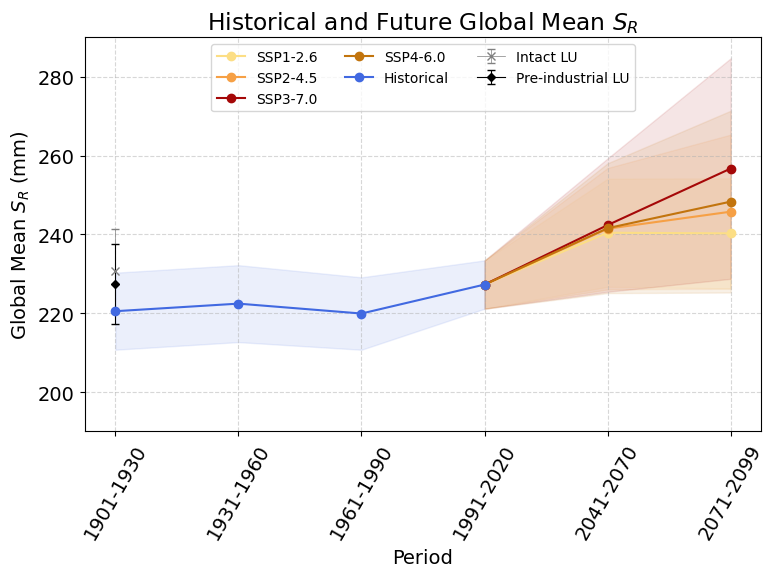

In [32]:
# plot change over time as a line plot.
# X axis: climate scenario ordered by period (intact, pre-industrial, hisotorical, future
# Y axis: mean weighted SR. Disregard std
# data points: same clim X LU give the actual SR for that period. eg Clim 1901_1930 with LU 1901_1930.
# for intact LU, use 1901_1930 climate
# for pre-industrial LU, use 1901_1930 climate
# for historical LU, use the climate corresponding to the LU. eg for LU 1991_2020, use climate 1991_2020
# for future LU, use the corresponding future climate. eg for LU 2071_2099_ssp460, use climate 2071_2099_ssp460
# in future time periods, plot each SSP scenario separately. So for LU 2071_2099_ssp460, use climate 2071_2099_ssp460, and so on for the other SSPs.
# Use a suitable color scheme to differentiate the scenarios, and include a legend

# handle different trajectories by drawing seperate lines
# one for intact, pre-industrial, historical
# one each for 4 ssps in future

plt.figure(figsize=(8, 6))
plt.rcParams.update({'font.size': 14})

ssp_labels = {
    '126': 'SSP1-2.6',
    '245': 'SSP2-4.5',
    '370': 'SSP3-7.0',
    '460': 'SSP4-6.0'
}
ssp_colors = {
    '126': "#FCDE85",
    '245': "#f6a045",
    '460': "#c2740d",
    '370': "#a50808",
}
# future scenarios using era = Future and seperate lines for each SSP
future_data = df_plot[df_plot['era'] == 'Future']
for ssp in future_data['ssp'].unique():
    ssp_data = future_data[future_data['ssp'] == ssp]
    plt.plot(ssp_data['time_step'], ssp_data['mean_weighted'], marker='o', label=ssp_labels[ssp], color=ssp_colors[ssp])
    # shade std around the mean
    plt.fill_between(ssp_data['time_step'], ssp_data['mean_weighted'] - ssp_data['std_weighted'], ssp_data['mean_weighted'] + ssp_data['std_weighted'], color=ssp_colors[ssp], alpha=0.1)

# points for intact and pre-industrial with error bars using std
intact_data = df_plot[df_plot['era'] == 'Intact']
#plt.plot(intact_data['time_step'], intact_data['mean_weighted'], marker='x', ms = 6, c='grey', lw=0.5,  label='Intact LU')
plt.errorbar(intact_data['time_step'], intact_data['mean_weighted'], yerr=intact_data['std_weighted'], marker='x', ms = 6, c='grey', lw=0.5,  label='Intact LU', capsize=3)

pi_data = df_plot[df_plot['era'] == 'PI']
#plt.plot(pi_data['time_step'], pi_data['mean_weighted'], marker='D', ms = 6, c='grey', lw=0.5,  label='PI LU')
plt.errorbar(pi_data['time_step'], pi_data['mean_weighted'], yerr=pi_data['std_weighted'], marker='D', ms = 4, c='black', lw=0.8,  label='Pre-industrial LU', capsize=3)

# Historical using era = Past
past_data = df_plot[df_plot['era'] == 'Past']
plt.plot(past_data['time_step'], past_data['mean_weighted'], marker='o', label='Historical', color='royalblue')
# shade std around the mean
plt.fill_between(past_data['time_step'], past_data['mean_weighted'] - past_data['std_weighted'], past_data['mean_weighted'] + past_data['std_weighted'], color='royalblue', alpha=0.1)

plt.xlabel('Period')
plt.ylabel('Global Mean $S_R$ (mm)')
plt.title('Historical and Future Global Mean $S_R$')
# label x ticks with the time_label values corresponding to the time_step values
time_labels = df_plot.drop_duplicates('time_step').sort_values('time_step')[['time_step', 'time_label']].set_index('time_step')['time_label']
plt.xticks(ticks=time_labels.index, labels=time_labels.values)
plt.ylim(190,290)
plt.xticks(rotation=60)
plt.legend(loc='upper center', frameon=True, fontsize=10, ncol=3)
plt.tight_layout()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


<>:115: SyntaxWarning: invalid escape sequence '\D'
<>:119: SyntaxWarning: invalid escape sequence '\D'
<>:115: SyntaxWarning: invalid escape sequence '\D'
<>:119: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2144120/2928166594.py:115: SyntaxWarning: invalid escape sequence '\D'
  label='$\Delta$ Climate' if i==0 else "", zorder=3)
/tmp/ipykernel_2144120/2928166594.py:119: SyntaxWarning: invalid escape sequence '\D'
  label='$\Delta$ Land Use' if i==0 else "", zorder=3)


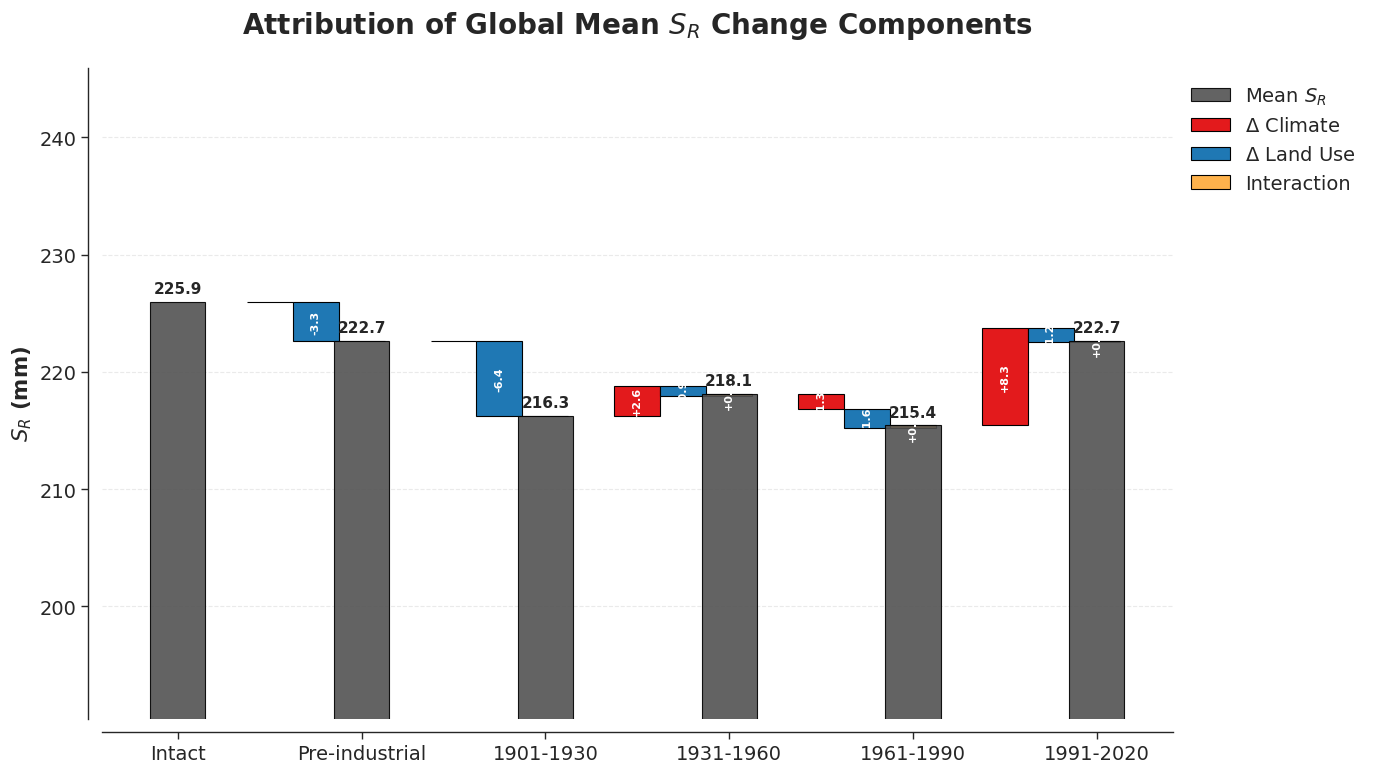

In [44]:
# bar plot of change
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from pathlib import Path

# Load data
df = pd.read_csv("/home/vajira/SRchange/output_SR/sr_scn_stats_k6_staticMaskSuper.csv")

# Mapping for display
period_labels = {
    "intact": "Intact",
    "pre-industrial": "Pre-industrial",
    "1901_1930": "1901-1930",
    "1931_1960": "1931-1960",
    "1961_1990": "1961-1990",
    "1991_2020": "1991-2020"
}

historical_periods = ["intact", "pre-industrial", "1901_1930", "1931_1960", "1961_1990", "1991_2020"]

def get_sr(clim, lu):
    # Map 'intact' and 'pre-industrial' LU to 1901_1930 climate if not explicit
    c = "1901_1930" if clim in ["intact", "pre-industrial"] else clim
    l = lu
    val = df[(df['climate'] == c) & (df['LU'] == l)]['mean_weighted']
    return val.values[0] if len(val) > 0 else None

# Calculate transitions
# Transition i -> i+1
# Global Mean (i)
# Climate effect: (Clim_i+1, LU_i) - (Clim_i, LU_i)
# LU effect: (Clim_i, LU_i+1) - (Clim_i, LU_i)
# Interaction/Residual: Total_Change - (Clim_effect + LU_effect)
# where Total_Change = (Clim_i+1, LU_i+1) - (Clim_i, LU_i)

data = []
for i in range(len(historical_periods)):
    p_curr = historical_periods[i]
    sr_curr = get_sr(p_curr, p_curr)
    
    entry = {
        "period": p_curr,
        "sr_mean": sr_curr,
        "clim_delta": 0,
        "lu_delta": 0,
        "inter_delta": 0
    }
    
    if i < len(historical_periods) - 1:
        p_next = historical_periods[i+1]
        sr_next = get_sr(p_next, p_next)
        
        # Isolate effects
        # Delta Climate = (Clim_next, LU_curr) - (Clim_curr, LU_curr)
        d_clim = get_sr(p_next, p_curr) - sr_curr
        
        # Delta LU = (Clim_curr, LU_next) - (Clim_curr, LU_curr)
        d_lu = get_sr(p_curr, p_next) - sr_curr
        
        # Interaction = Total Change - (d_clim + d_lu)
        total_delta = sr_next - sr_curr
        d_inter = total_delta - (d_clim + d_lu)
        
        entry.update({
            "clim_delta": d_clim,
            "lu_delta": d_lu,
            "inter_delta": d_inter
        })
    
    data.append(entry)

plot_df = pd.DataFrame(data)

# Visualizing as a "Waterfall-esque" or Step-wise Attribution Plot
plt.figure(figsize=(14, 8))
sns.set_style("ticks")
sns.set_context("paper", font_scale=1.6)

x = np.arange(len(plot_df))
width = 0.2

color_mean = "#525252"
color_clim = "#e31a1c"
color_lu = "#1f78b4"
color_inter = "#feb24c"

# Plotting each period
for i in range(len(plot_df)):
    curr_sr = plot_df.loc[i, 'sr_mean']
    
    # Position for the main bar
    x_base = i
    
    # 1. Main SR bar
    plt.bar(x_base, curr_sr, width*1.5, color=color_mean, edgecolor='black', alpha=0.9, label='Mean $S_R$' if i==0 else "", zorder=3)
    plt.text(x_base, curr_sr + 0.5, f"{curr_sr:.1f}", ha='center', va='bottom', fontweight='bold', fontsize=11, zorder=4)
    
    # 2. Change bars for the transition to NEXT period (if not last)
    if i < len(plot_df) - 1:
        d_clim = plot_df.loc[i, 'clim_delta']
        d_lu = plot_df.loc[i, 'lu_delta']
        d_inter = plot_df.loc[i, 'inter_delta']
        
        # We start the climate bar from the current SR
        # Then LU bar starts from SR + Clim_delta
        # Then Inter bar starts from SR + Clim_delta + LU_delta
        
        x_step = i + 0.5 # Shifted to the right between periods
        step_w = 0.25
        
        # Climate bar
        plt.bar(x_step, d_clim, step_w, bottom=curr_sr, color=color_clim, edgecolor='black', 
                label='$\Delta$ Climate' if i==0 else "", zorder=3)
        
        # LU bar
        plt.bar(x_step + step_w, d_lu, step_w, bottom=curr_sr + d_clim, color=color_lu, edgecolor='black', 
                label='$\Delta$ Land Use' if i==0 else "", zorder=3)
        
        # Interaction bar
        plt.bar(x_step + 2*step_w, d_inter, step_w, bottom=curr_sr + d_clim + d_lu, color=color_inter, edgecolor='black', 
                label='Interaction' if i==0 else "", zorder=3)
        
        # Add labels for deltas
        for val, x_pos, b_pos in zip([d_clim, d_lu, d_inter], 
                                     [x_step, x_step + step_w, x_step + 2*step_w],
                                     [curr_sr, curr_sr + d_clim, curr_sr + d_clim + d_lu]):
            if abs(val) > 0.05:
                # Place text above or below the delta bar
                y_txt = b_pos + val/2
                plt.text(x_pos, y_txt, f"{val:+.1f}", ha='center', va='center', fontsize=8, 
                         color='white', fontweight='bold', rotation=90, zorder=5)

# Aesthetics
plt.xticks(x, [period_labels[p] for p in plot_df['period']])
plt.ylabel("$S_R$ (mm)", fontweight='bold')
plt.title("Attribution of Global Mean $S_R$ Change Components", fontsize=20, pad=25, fontweight='bold')

plt.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
sns.despine(offset=10)
plt.grid(axis='y', linestyle='--', alpha=0.4)

# Adjust y-axis to focus on the top part
ymin = plot_df['sr_mean'].min() - 25
ymax = (plot_df['sr_mean'].max() + 20)
plt.ylim(ymin, ymax)

plt.tight_layout()
plt.show()
#plt.savefig(output_dir / "sr_change_step_attribution.png", dpi=300, bbox_inches='tight')
#plt.savefig(output_dir / "sr_change_step_attribution.pdf", bbox_inches='tight')

In [45]:
plot_df

,period,sr_mean,clim_delta,lu_delta,inter_delta
0,intact,225.938679,0.000000,-3.282120,0.000000
1,pre-industrial,222.656558,0.000000,-6.404737,0.000000
2,1901_1930,216.251821,2.586744,-0.885927,0.186995
3,1931_1960,218.139633,-1.342511,-1.597430,0.231821
4,1961_1990,215.431512,8.325321,-1.187204,0.107261
5,1991_2020,222.676891,0.000000,0.000000,0.000000


In [9]:
# compare to alternative SR
# calculate recent SR change using xi et al SR series (1981-2020) and compare with
# deltaSR_recent calculated from our model for the same period (1991-2020 vs 1961-1990)

xiSR = xr.open_dataarray("../data/alt-SR/sr_Xi_1982to2020_0p5.nc")
xiSR_1982_1990 = xiSR.sel(year=slice(1982, 1990)).mean('year')
xiSR_2012_2020 = xiSR.sel(year=slice(2012, 2020)).mean('year')
deltaSR_recent_xi = xiSR_2012_2020 - xiSR_1982_1990


In [10]:
deltaSR_recent_0p5 = deltaSR_recent.coarsen(lat=10, lon=10, boundary='trim').median() # coarsen to 0.5 degree resolution
deltaSR_recent_xi = deltaSR_recent_xi.interp_like(deltaSR_recent_0p5, method='nearest') # interpolate to same grid as xiSR

# mutually mask the two arrays to ensure we only compare valid data points
valid_mask = np.isfinite(deltaSR_recent_0p5) & np.isfinite(deltaSR_recent_xi)
deltaSR_recent_0p5 = deltaSR_recent_0p5.where(valid_mask)
deltaSR_recent_xi = deltaSR_recent_xi.where(valid_mask)

deltaSR_recent_xi_mean, deltaSR_recent_xi_std = global_stats(deltaSR_recent_xi, weighted=True)
print(f"Change in SR (1991-2020 vs 1982-1990) from Xi et al. dataset: {deltaSR_recent_xi_mean:.2f} ± {deltaSR_recent_xi_std:.2f} mm")

deltaSR_recent_0p5_mean, deltaSR_recent_0p5_std = global_stats(deltaSR_recent_0p5, weighted=True)
print(f"Change in SR (1991-2020 vs 1961-1990) from our model: {deltaSR_recent_0p5_mean:.2f} ± {deltaSR_recent_0p5_std:.2f} mm")

Change in SR (1991-2020 vs 1982-1990) from Xi et al. dataset: 15.51 ± 67.37 mm
Change in SR (1991-2020 vs 1961-1990) from our model: 7.08 ± 36.89 mm


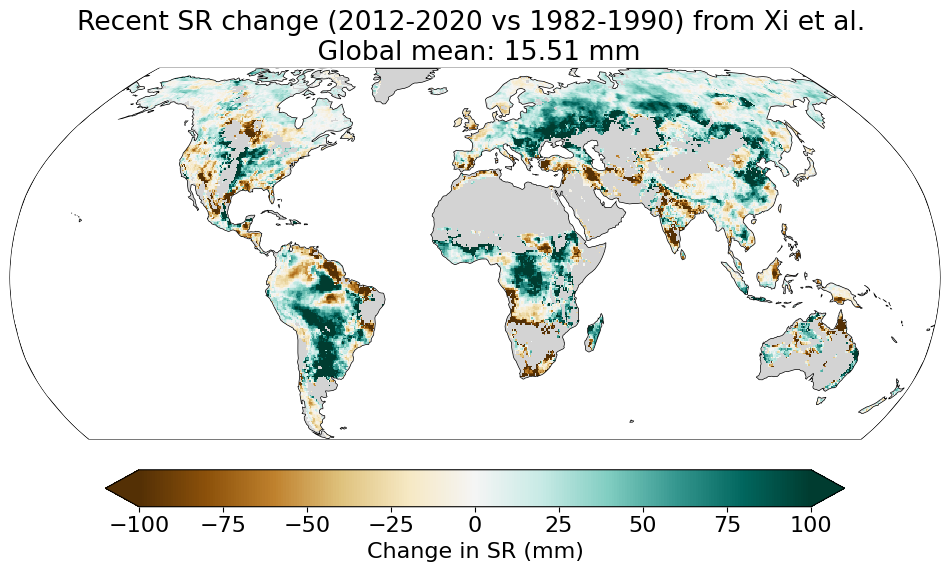

In [21]:
plot_map(deltaSR_recent_xi, title=f'Recent SR change (2012-2020 vs 1982-1990) from Xi et al. \n Global mean: {deltaSR_recent_xi_mean:.2f} mm', cmap='BrBG', vmin=-100, vmax=100, cbar_label='Change in SR (mm)')

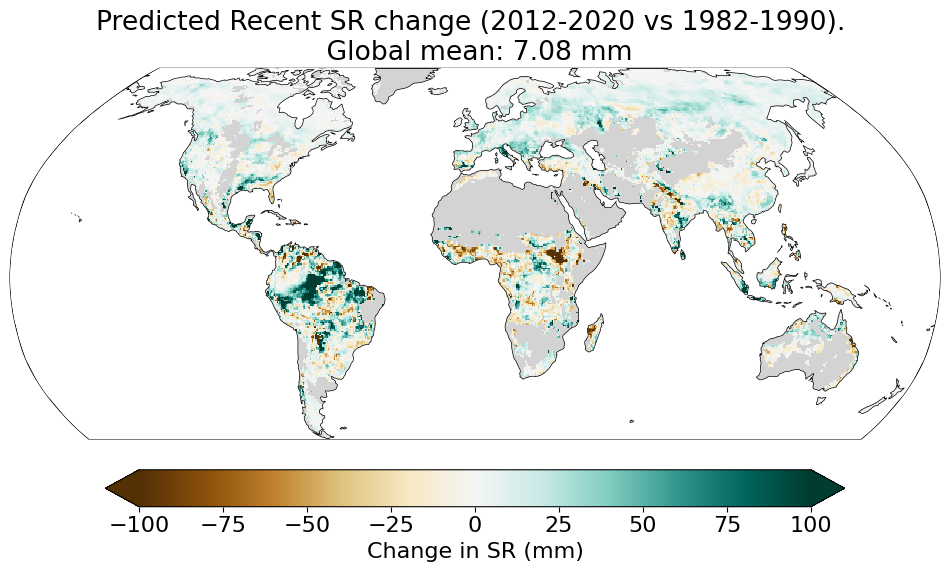

In [22]:
plot_map(deltaSR_recent_0p5, title=f'Predicted Recent SR change (2012-2020 vs 1982-1990). \n Global mean: {deltaSR_recent_0p5_mean:.2f} mm', cmap='BrBG', vmin=-100, vmax=100, cbar_label='Change in SR (mm)')

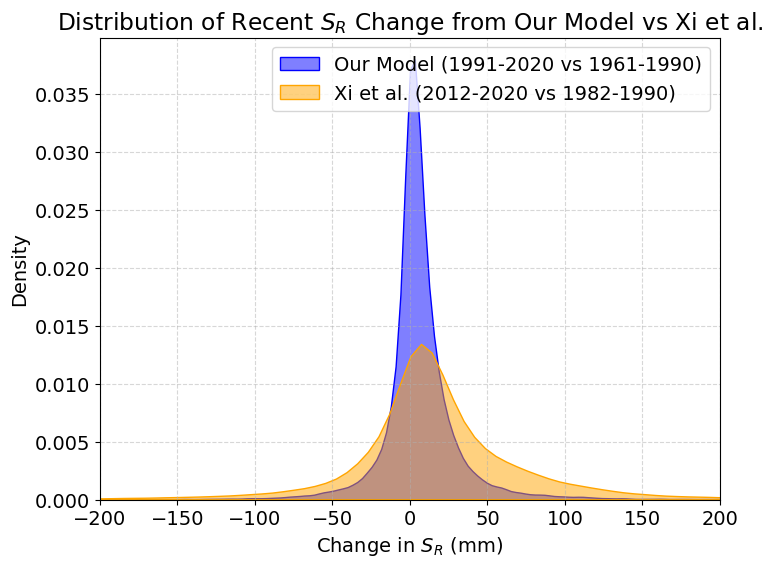

In [54]:
# plot the 2 deltaSR arrays as density plots in a single plot to compare their distributions
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.kdeplot(deltaSR_recent_0p5.values.flatten(), label='Our Model (1991-2020 vs 1961-1990)', fill=True, color='blue', alpha=0.5)
sns.kdeplot(deltaSR_recent_xi.values.flatten(), label='Xi et al. (2012-2020 vs 1982-1990)', fill=True, color='orange', alpha=0.5)
plt.xlabel('Change in $S_R$ (mm)')
plt.title('Distribution of Recent $S_R$ Change from Our Model vs Xi et al.')
plt.xlim(-200, 200)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


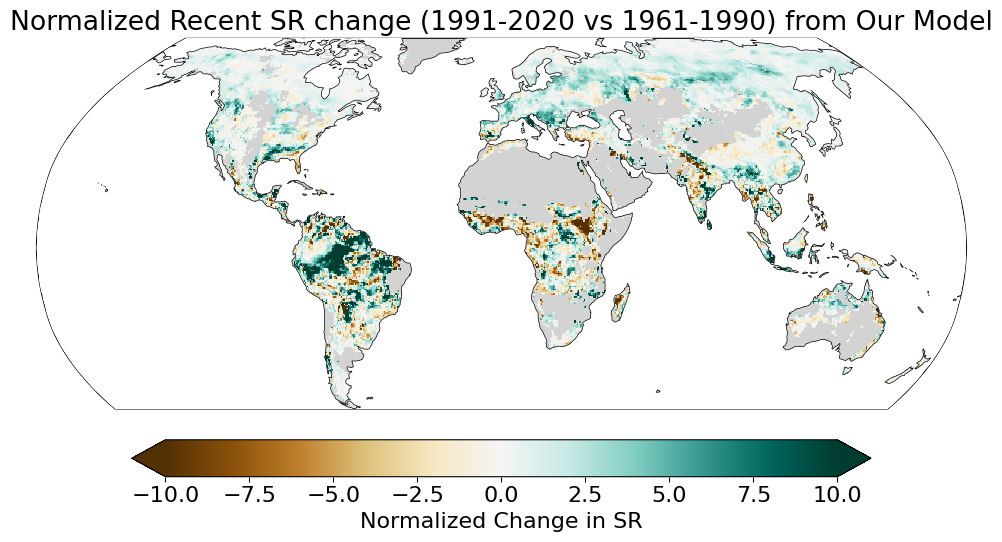

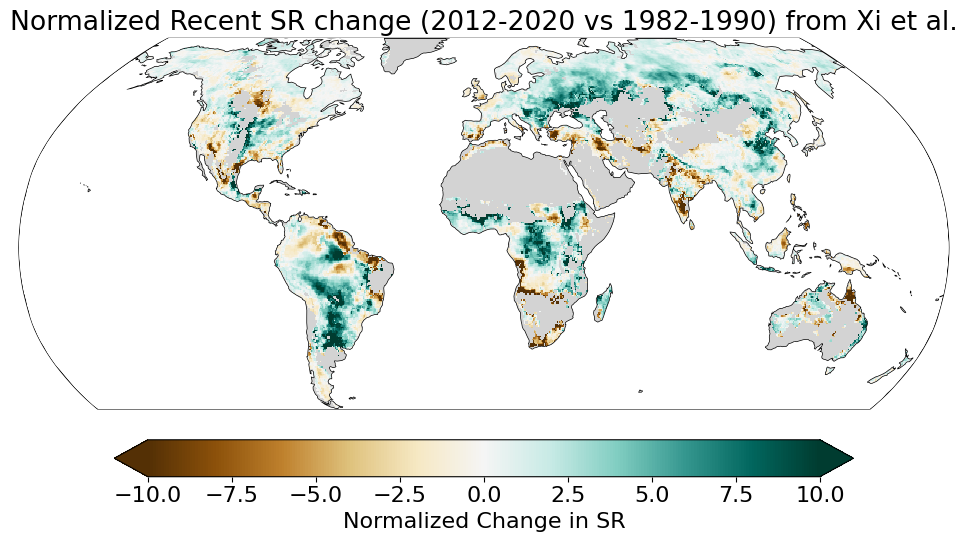

In [17]:
# normalize the deltaSR_recent_0p5 and deltaSR_recent_xi arrays by their global mean values to compare their spatial patterns without the influence of their different magnitudes. Then plot them side by side to visually compare their spatial patterns.
deltaSR_recent_0p5_norm = deltaSR_recent_0p5 / deltaSR_recent_0p5_mean
deltaSR_recent_xi_norm = deltaSR_recent_xi / deltaSR_recent_xi_mean
plot_map(deltaSR_recent_0p5_norm, title=f'Normalized Recent SR change (1991-2020 vs 1961-1990) from Our Model', cmap='BrBG', vmin=-10, vmax=10, cbar_label='Normalized Change in SR')
plot_map(deltaSR_recent_xi_norm, title=f'Normalized Recent SR change (2012-2020 vs 1982-1990) from Xi et al.', cmap='BrBG', vmin=-10, vmax=10, cbar_label='Normalized Change in SR')


In [14]:
# standardize the two datasets (z-score) and then plot them against each other in a scatter plot to see how well they correlate spatially
deltaSR_recent_0p5_z = (deltaSR_recent_0p5 - deltaSR_recent_0p5.weighted(np.cos(np.deg2rad(deltaSR_recent_0p5['lat']))).mean()) / deltaSR_recent_0p5.weighted(np.cos(np.deg2rad(deltaSR_recent_0p5['lat']))).std()
deltaSR_recent_xi_z = (deltaSR_recent_xi - deltaSR_recent_xi.weighted(np.cos(np.deg2rad(deltaSR_recent_xi['lat']))).mean()) / deltaSR_recent_xi.weighted(np.cos(np.deg2rad(deltaSR_recent_xi['lat']))).std()
# mutually mask the two arrays again after standardization
valid_mask_z = np.isfinite(deltaSR_recent_0p5_z) & np.isfinite(deltaSR_recent_xi_z)
deltaSR_recent_0p5_z = deltaSR_recent_0p5_z.where(valid_mask_z, drop=True)
deltaSR_recent_xi_z = deltaSR_recent_xi_z.where(valid_mask_z, drop=True)

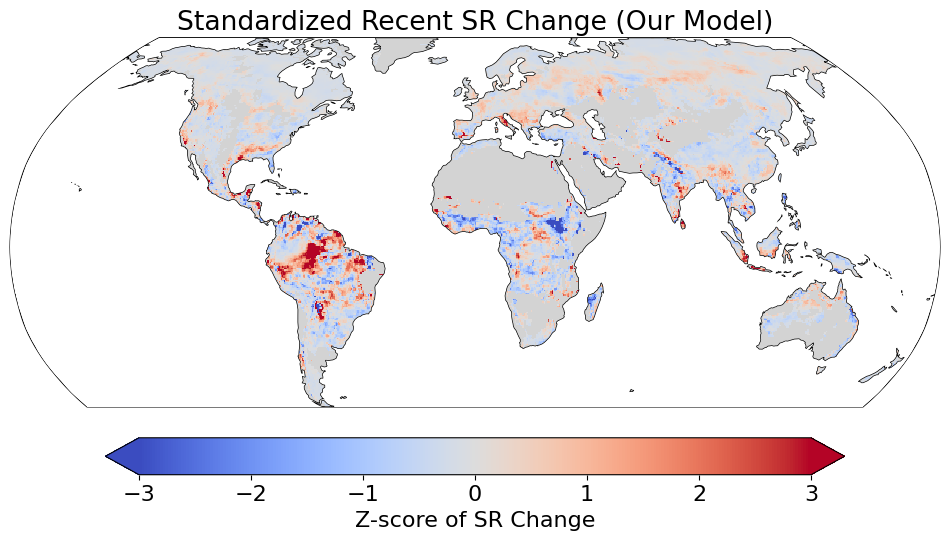

In [19]:
plot_map(deltaSR_recent_0p5_z, title='Standardized Recent SR Change (Our Model)', cmap='coolwarm', vmin=-3, vmax=3, cbar_label='Z-score of SR Change')

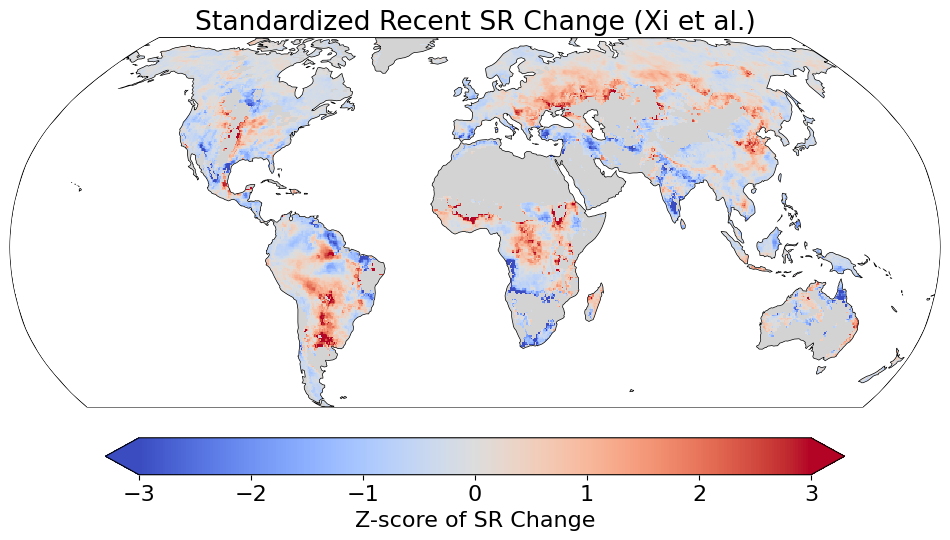

In [20]:
plot_map(deltaSR_recent_xi_z, title='Standardized Recent SR Change (Xi et al.)', cmap='coolwarm', vmin=-3, vmax=3, cbar_label='Z-score of SR Change')

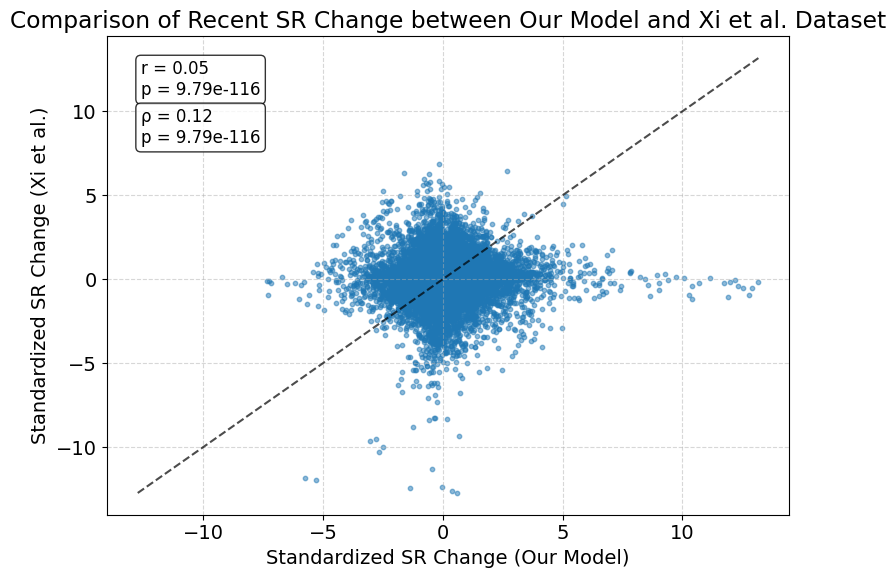

In [59]:
# plot scatter plot between the two standardized datasets
from scipy.stats import pearsonr
from scipy.stats import spearmanr
# flatten the data and remove NaNs for correlation calculation
deltaSR_recent_0p5_z_flat = deltaSR_recent_0p5_z.values.flatten()
deltaSR_recent_xi_z_flat = deltaSR_recent_xi_z.values.flatten()
deltaSR_recent_0p5_z_flat = deltaSR_recent_0p5_z_flat[np.isfinite(deltaSR_recent_0p5_z_flat)]
deltaSR_recent_xi_z_flat = deltaSR_recent_xi_z_flat[np.isfinite(deltaSR_recent_xi_z_flat)]

plt.figure(figsize=(8, 6))
plt.scatter(deltaSR_recent_0p5_z_flat, deltaSR_recent_xi_z_flat, alpha=0.5, s=10)
plt.xlabel('Standardized SR Change (Our Model)')
plt.ylabel('Standardized SR Change (Xi et al.)')
plt.title('Comparison of Recent SR Change between Our Model and Xi et al. Dataset')
# add a 1:1 line
lims = [np.nanmin([deltaSR_recent_0p5_z.min(), deltaSR_recent_xi_z.min()]), np.nanmax([deltaSR_recent_0p5_z.max(), deltaSR_recent_xi_z.max()])]
plt.plot(lims, lims, 'k--', alpha=0.7)
# calculate and display the correlation coefficient
pearson_corr, p_value = pearsonr(deltaSR_recent_0p5_z_flat, deltaSR_recent_xi_z_flat)
spearman_corr, p_value = spearmanr(deltaSR_recent_0p5_z_flat, deltaSR_recent_xi_z_flat)

plt.text(0.05, 0.95, f"r = {pearson_corr:.2f}\np = {p_value:.2e}", transform=plt.gca().transAxes, ha='left', va='top', fontsize=12, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.text(0.05, 0.85, f"ρ = {spearman_corr:.2f}\np = {p_value:.2e}", transform=plt.gca().transAxes, ha='left', va='top', fontsize=12, bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [60]:
# calculate the sign agreement
sign_agreement = xr.where(((deltaSR_recent_0p5 > 0) & (deltaSR_recent_xi > 0)) | ((deltaSR_recent_0p5 < 0) & (deltaSR_recent_xi < 0)), 1, 0)
sign_disagreement = xr.where(((deltaSR_recent_0p5 > 0) & (deltaSR_recent_xi < 0)) | ((deltaSR_recent_0p5 < 0) & (deltaSR_recent_xi > 0)), 1, 0)
both_increase = xr.where((deltaSR_recent_0p5 > 0) & (deltaSR_recent_xi > 0), 1, 0)
both_decrease = xr.where((deltaSR_recent_0p5 < 0) & (deltaSR_recent_xi < 0), 1, 0)
valid_mask = np.isfinite(deltaSR_recent_0p5) & np.isfinite(deltaSR_recent_xi)
agreement_percentage = (sign_agreement.where(valid_mask).sum().item() / valid_mask.sum().item()) * 100
print(f"Sign agreement between model and Xi SR change: {agreement_percentage:.2f}%")

Sign agreement between model and Xi SR change: 60.18%


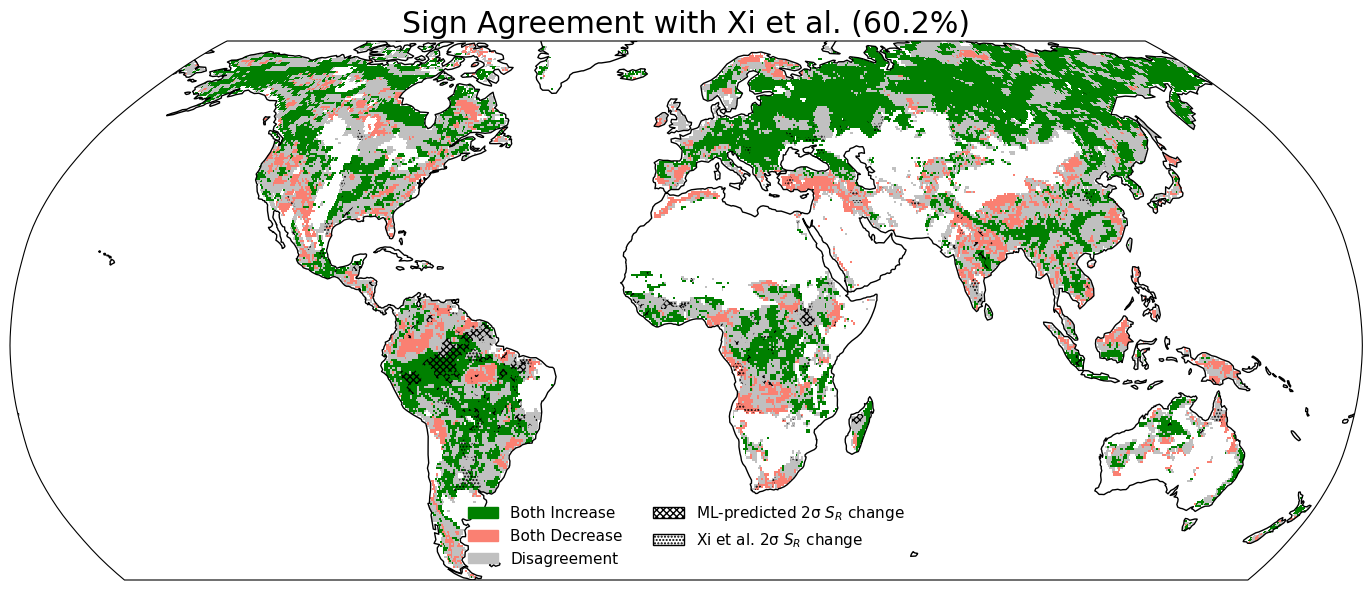

In [61]:
# plot agreeing increase, agreeing decrease, and disagreement areas
# custom cmap with 3 colors
# custom legend using matplotlib patches

import matplotlib.patches as mpatches
from matplotlib import colors

agreeing_change = xr.where(both_increase, 1, xr.where(both_decrease, -1, xr.where(sign_disagreement!=0, 0, np.nan))) # 1 for agreeing increase, -1 for agreeing decrease, 0 for disagreement, NaN for invalid
cmap_3color = colors.ListedColormap(['salmon', 'silver', 'green'])

# create masks for 2 sigma + change in each dataset to hatch
ml_2sigma = deltaSR_recent_0p5_std * 2
xi_2sigma = deltaSR_recent_xi_std * 2
ml_2sigma_mask = xr.where(np.abs(deltaSR_recent_0p5) > ml_2sigma, 1, 0)
xi_2sigma_mask = xr.where(np.abs(deltaSR_recent_xi) > xi_2sigma, 1, 0)

plt.rcParams.update({'font.size': 18})
plt.figure(figsize=(21, 7))
ax = plt.axes(projection=ccrs.Robinson())
agreeing_change.plot(cmap=cmap_3color, transform=ccrs.PlateCarree(), add_colorbar=False) #  hide cbar
# add hatching for areas where change is greater than 2 sigma in either dataset. use countourf
xr.plot.contourf(xr.where(ml_2sigma_mask, 1, np.nan), colors='none', hatches=['xxxxx'], transform=ccrs.PlateCarree(), add_colorbar=False)
xr.plot.contourf(xr.where(xi_2sigma_mask, 1, np.nan), colors='none', hatches=['.....'], transform=ccrs.PlateCarree(), add_colorbar=False)

ax.coastlines() # coastlines for context
ax.set_title(f'Sign Agreement with Xi et al. ({agreement_percentage:.1f}%)' )

# patches for change
increase_patch = mpatches.Patch(color='green', label='Both Increase')
decrease_patch = mpatches.Patch(color='salmon', label='Both Decrease')
disagree_patch = mpatches.Patch(color='silver', label='Disagreement')
# patches for hatching
ml_2sigma_patch = mpatches.Patch(hatch='xxxxx', fill=False, label='ML-predicted 2σ $S_R$ change')
xi_2sigma_patch = mpatches.Patch(hatch='.....', fill=False, label='Xi et al. 2σ $S_R$ change')

plt.legend(handles=[increase_patch, decrease_patch, disagree_patch, ml_2sigma_patch, xi_2sigma_patch], loc='lower center', frameon=False, fontsize=11, ncol=2)

    
plt.show()


In [62]:
# sign agreement excluding the smallest change
# alignment of only the top 90% increasing and decreasing areas in both datasets

threshold_level = 0.4 # 20% threshold for significant change
threshold_increase_ml = deltaSR_recent_0p5.where(deltaSR_recent_0p5 > 0).quantile(threshold_level)
threshold_decrease_ml = deltaSR_recent_0p5.where(deltaSR_recent_0p5 < 0).quantile(1 - threshold_level)
threshold_increase_xi = deltaSR_recent_xi.where(deltaSR_recent_xi > 0).quantile(threshold_level)
threshold_decrease_xi = deltaSR_recent_xi.where(deltaSR_recent_xi < 0).quantile(1 - threshold_level)

print(f"Threshold for significant increase in model: {threshold_increase_ml:.2f} mm")
print(f"Threshold for significant decrease in model: {threshold_decrease_ml:.2f} mm")
print(f"Threshold for significant increase in Xi dataset: {threshold_increase_xi:.2f} mm")
print(f"Threshold for significant decrease in Xi dataset: {threshold_decrease_xi:.2f} mm")

significant_change_ml = xr.where((deltaSR_recent_0p5 >= threshold_increase_ml) | (deltaSR_recent_0p5 <= threshold_decrease_ml), 1, 0)
significant_change_xi = xr.where((deltaSR_recent_xi >= threshold_increase_xi) | (deltaSR_recent_xi <= threshold_decrease_xi), 1, 0)
# hotspot_agreement = xr.where(sign_agreement & significant_change_ml & significant_change_xi, 1, 0)

minor_change_mask = xr.where((deltaSR_recent_0p5 < threshold_increase_ml) & (deltaSR_recent_0p5 > threshold_decrease_ml)
                              & (deltaSR_recent_xi < threshold_increase_xi) & (deltaSR_recent_xi > threshold_decrease_xi), 1, 0)

hotspot_agreement = xr.where(sign_agreement & (1 - minor_change_mask), 1, 0) # agreement in sign and not minor change in both datasets

union_mask = xr.where(((significant_change_ml == 1) | (significant_change_xi == 1)) & valid_mask, 1, 0)

pct_union_agree = (hotspot_agreement.sum().item() / union_mask.sum().item()) * 100
pct_union = (union_mask.sum().item() / valid_mask.sum().item()) * 100
hotspot_agreement_percentage = (hotspot_agreement.sum().item() / valid_mask.sum().item()) * 100
print(f"Hotspot agreement between model and Xi SR change: {hotspot_agreement_percentage:.2f}%")
print(f"Union of significant change areas in model and Xi dataset: {pct_union:.2f}%")
print(f"Agreement in hotspots as percentage of union of significant change areas: {pct_union_agree:.2f}%")


Threshold for significant increase in model: 6.67 mm
Threshold for significant decrease in model: -4.26 mm
Threshold for significant increase in Xi dataset: 19.63 mm
Threshold for significant decrease in Xi dataset: -13.62 mm
Hotspot agreement between model and Xi SR change: 47.41%
Union of significant change areas in model and Xi dataset: 78.49%
Agreement in hotspots as percentage of union of significant change areas: 60.40%


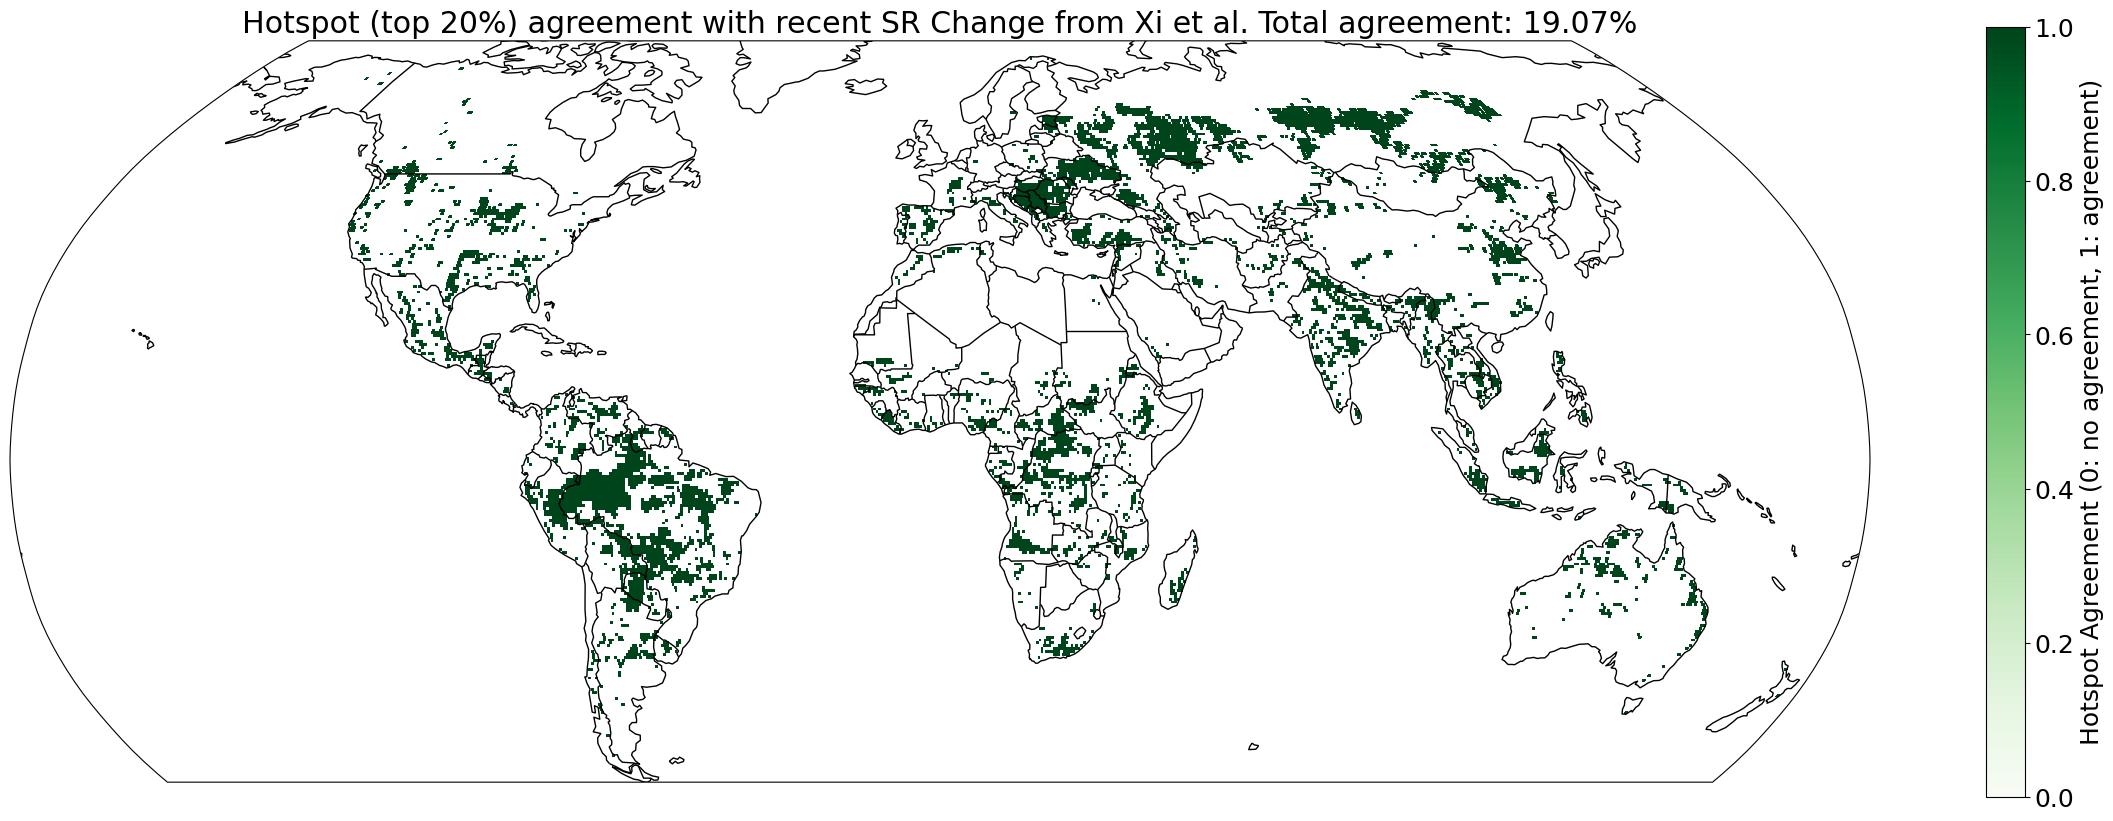

In [44]:
# plot hotspot agreement
plot_map(hotspot_agreement.where(hotspot_agreement), title=f'Hotspot (top 20%) agreement with recent SR Change from Xi et al. Total agreement: {hotspot_agreement_percentage:.2f}%', cmap='Greens', vmin=0, vmax=1, borders=True, cbar_label='Hotspot Agreement (0: no agreement, 1: agreement)')

In [63]:
import numpy as np
import pandas as pd
import xarray as xr

def hotspot_agreement_vs_threshold(
    deltaSR_ml,
    deltaSR_xi,
    valid_mask,
    thresholds=np.arange(0.0, 1.0, 0.05),
):
    """
    Compute hotspot agreement percentage for a range of threshold values.

    Parameters
    ----------
    deltaSR_ml    : xr.DataArray  – ML delta SR field
    deltaSR_xi    : xr.DataArray  – Xi delta SR field
    valid_mask    : xr.DataArray  – boolean mask of valid pixels
    thresholds    : array-like    – threshold levels in [0, 1) to sweep

    Returns
    -------
    pd.DataFrame with columns [threshold, hotspot_agreement_pct, significant_pct]
    """
    hotspot_agreement_records = []
    hotspot_union_records = []

    sign_agree = xr.where(((deltaSR_ml > 0) & (deltaSR_xi > 0)) | ((deltaSR_ml < 0) & (deltaSR_xi < 0)), 1, 0)

    for t in thresholds:
        # --- quantile cuts (positive tail lower bound, negative tail upper bound)
        thr_inc_ml = deltaSR_ml.where(deltaSR_ml > 0).quantile(t)
        thr_dec_ml = deltaSR_ml.where(deltaSR_ml < 0).quantile(1 - t)
        thr_inc_xi = deltaSR_xi.where(deltaSR_xi > 0).quantile(t)
        thr_dec_xi = deltaSR_xi.where(deltaSR_xi < 0).quantile(1 - t)

        sig_ml = xr.where((deltaSR_ml >= thr_inc_ml) | (deltaSR_ml <= thr_dec_ml), 1, 0)
        sig_xi = xr.where((deltaSR_xi >= thr_inc_xi) | (deltaSR_xi <= thr_dec_xi), 1, 0)

        # --- flag significant pixels in each dataset (1 if above positive threshold, -1 below negative threshold, else 0)
        #sig_ml = xr.where((deltaSR_ml >= thr_inc_ml), 1, xr.where((deltaSR_ml <= thr_dec_ml), -1, 0))
        #sig_xi = xr.where((deltaSR_xi >= thr_inc_xi), 1, xr.where((deltaSR_xi <= thr_dec_xi), -1, 0))

        minor_change = xr.where((deltaSR_ml < thr_inc_ml) & (deltaSR_ml > thr_dec_ml) &
                                (deltaSR_xi < thr_inc_xi) & (deltaSR_xi > thr_dec_xi), 1, 0)

        # --- hotspot agreement: both flagged AND inside valid mask
        #hotspot_agreement = xr.where(sign_agree & (sig_ml != 0) & (sig_xi != 0), 1, 0)
        hotspot_agreement = xr.where(sign_agree & (1-minor_change), 1, 0) # agreement in sign and not minor change in both datasets

        # get union for cells significant in either dataset (for percentage calculation)
        union = xr.where(((sig_ml == 1) | (sig_xi == 1)) & valid_mask, 1, 0)

        pct = (hotspot_agreement.sum().item() / union.sum().item()) * 100
        hotspot_agreement_records.append({"threshold": round(float(t), 4), "hotspot_agreement_pct": pct})

        pct_union = (union.sum().item() / valid_mask.sum().item()) * 100
        hotspot_union_records.append({"threshold": round(float(t), 4), "significant_pct": pct_union})
    
    # create a single dataframe with both agreement and union percentages
    df_agreement = pd.DataFrame(hotspot_agreement_records)
    df_union = pd.DataFrame(hotspot_union_records)
    df_result = pd.merge(df_agreement, df_union, on="threshold")
    return df_result

thresholds = np.arange(0.0, 1.0, 0.05)   # 0, 0.05, 0.10, … 0.95
df_hotspot = hotspot_agreement_vs_threshold(
    deltaSR_recent_0p5, deltaSR_recent_xi, valid_mask, thresholds
)
print(df_hotspot)

    threshold  hotspot_agreement_pct  significant_pct
0        0.00              60.180645       100.000000
1        0.05              60.191784        99.574194
2        0.10              60.201941        98.400000
3        0.15              60.306302        96.552258
4        0.20              60.304170        94.005161
5        0.25              60.364400        90.931613
6        0.30              60.437417        87.316129
7        0.35              60.361479        83.099355
8        0.40              60.404406        78.490323
9        0.45              60.375771        73.620645
10       0.50              60.333534        68.552258
11       0.55              60.103669        63.228387
12       0.60              59.846788        57.605161
13       0.65              59.805864        52.108387
14       0.70              59.595395        46.178065
15       0.75              59.644917        39.827097
16       0.80              59.241964        33.158710
17       0.85              5

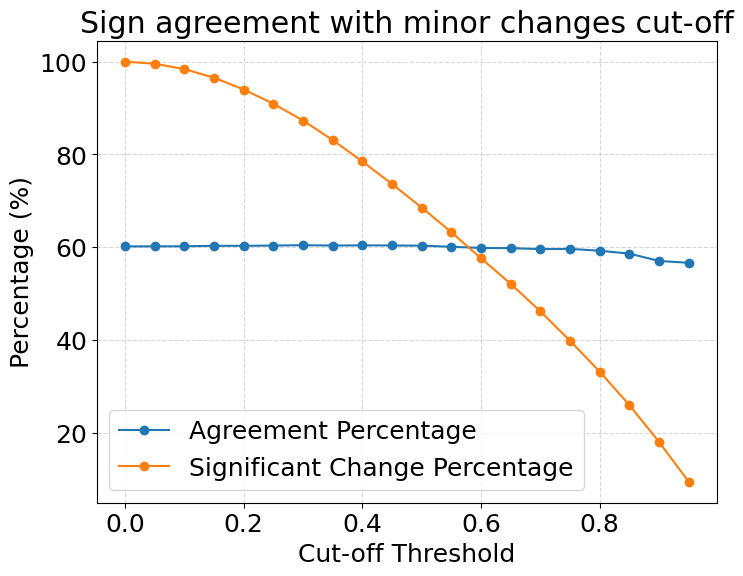

In [64]:
plt.figure(figsize=(8, 6))
plt.plot(df_hotspot['threshold'], df_hotspot['hotspot_agreement_pct'], marker='o', label='Agreement Percentage')
plt.plot(df_hotspot['threshold'], df_hotspot['significant_pct'], marker='o', label='Significant Change Percentage')
plt.xlabel('Cut-off Threshold')
plt.ylabel('Percentage (%)')
plt.title('Sign agreement with minor changes cut-off')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()